In [1]:
import json
import pickle
import re
import time
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
import shap
import shutil
from requests.exceptions import RequestException
from scipy import stats
from scipy.linalg import fractional_matrix_power
from sklearn.pipeline import make_pipeline

from sklearn.base import clone
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, balanced_accuracy_score
from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.neural_network import MLPClassifier
from sklearn.preprocessing import StandardScaler

from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from sklearn.exceptions import ConvergenceWarning

warnings.filterwarnings("ignore", message="X does not have valid feature names")

In [2]:
RANDOM_STATE = 42

RESULTS_DIR = Path("/kaggle/working/results")
SVG_DIR = Path("/kaggle/working/figures")
RAW_DATA_DIR = Path("/kaggle/working/raw_cohorts")

for directory in (RESULTS_DIR, SVG_DIR, RAW_DATA_DIR):
    directory.mkdir(parents=True, exist_ok=True)

In [3]:
def compute_audit(model, X_source, y_source, X_target, y_target,
                   n_permutations=1000, random_state=42, metric="accuracy"):
    
    if metric not in ("accuracy", "balanced_accuracy"):
        raise ValueError(f"metric must be 'accuracy' or 'balanced_accuracy', got {metric!r}")

    X_source = np.asarray(X_source, dtype=float)
    X_target = np.asarray(X_target, dtype=float)
    y_source = np.array(y_source)
    y_target = np.array(y_target)

    X_tr, X_te, y_tr, y_te = train_test_split(
        X_source, y_source, test_size=0.25, random_state=random_state, stratify=y_source
    )

    m = clone(model)
    m.fit(X_tr, y_tr)

    y_pred_source = m.predict(X_te)
    y_pred_target = m.predict(X_target)

    if metric == "accuracy":
        source_acc = float(accuracy_score(y_te, y_pred_source))
        target_acc = float(accuracy_score(y_target, y_pred_target))
        gap_pp = (source_acc - target_acc) * 100.0

        correct_s = (y_pred_source == y_te).astype(float)
        correct_t = (y_pred_target == y_target).astype(float)
        n_s, n_t = len(correct_s), len(correct_t)

        pooled = np.concatenate([correct_s, correct_t])
        rng = np.random.RandomState(random_state)
        perm_gaps = np.empty(n_permutations)
        for i in range(n_permutations):
            shuffled = rng.permutation(pooled)
            perm_gaps[i] = (shuffled[:n_s].mean() - shuffled[n_s:].mean()) * 100.0

        m1, m2 = correct_s.mean(), correct_t.mean()
        s1, s2 = correct_s.std(ddof=1), correct_t.std(ddof=1)
        pooled_sd = np.sqrt(((n_s - 1) * s1**2 + (n_t - 1) * s2**2) / (n_s + n_t - 2))
        cohen_d = float((m1 - m2) / pooled_sd) if pooled_sd > 0 else 0.0

    else:
        source_acc = float(balanced_accuracy_score(y_te, y_pred_source))
        target_acc = float(balanced_accuracy_score(y_target, y_pred_target))
        gap_pp = (source_acc - target_acc) * 100.0

        n_s, n_t = len(y_te), len(y_target)
        true_pooled = np.concatenate([y_te, y_target])
        pred_pooled = np.concatenate([y_pred_source, y_pred_target])
        idx = np.arange(n_s + n_t)
        rng = np.random.RandomState(random_state)

        perm_gaps = np.empty(n_permutations)
        for i in range(n_permutations):
            shuffled = rng.permutation(idx)
            g_s, g_t = shuffled[:n_s], shuffled[n_s:]
            perm_gaps[i] = (
                balanced_accuracy_score(true_pooled[g_s], pred_pooled[g_s])
                - balanced_accuracy_score(true_pooled[g_t], pred_pooled[g_t])
            ) * 100.0

        cohen_d = None

    p_value = float(np.mean(np.abs(perm_gaps) >= np.abs(gap_pp)))
    p_value = max(p_value, 1.0 / n_permutations)

    null_ci = np.percentile(perm_gaps, [2.5, 97.5])

    return {
        "gap_pp": gap_pp,
        "p_value": p_value,
        "cohen_d": cohen_d,
        "null_ci": (float(null_ci[0]), float(null_ci[1])),
        "source_accuracy": source_acc,
        "target_accuracy": target_acc,
        "n_source": int(len(X_source)),
        "n_target": int(len(X_target)),
        "trained_model": m,
        "perm_gaps": perm_gaps.tolist(),
        "metric": metric,
    }

In [4]:
def holm_bonferroni(p_values, alpha=0.05):
    
    p_values = np.asarray(p_values, dtype=float)
    n = len(p_values)
    order = np.argsort(p_values)
    sorted_p = p_values[order]

    adj_sorted = np.empty(n)
    running_max = 0.0
    for i in range(n):
        raw_adj = (n - i) * sorted_p[i]
        running_max = max(running_max, raw_adj)
        adj_sorted[i] = min(running_max, 1.0)

    reject_sorted = np.zeros(n, dtype=bool)
    still_rejecting = True
    for i in range(n):
        if still_rejecting and sorted_p[i] <= alpha / (n - i):
            reject_sorted[i] = True
        else:
            still_rejecting = False

    adj_p = np.empty(n)
    reject = np.empty(n, dtype=bool)
    adj_p[order] = adj_sorted
    reject[order] = reject_sorted
    return adj_p, reject

In [5]:
def run_per_algorithm_audit(base_algorithms, X_source, y_source, X_target, y_target,
                             metric="accuracy", n_permutations=1000, random_state=42, alpha=0.05):
    
    names = list(base_algorithms.keys())
    raw_results = {}
    raw_p = []

    for name in names:
        r = compute_audit(
            clone(base_algorithms[name]), X_source, y_source, X_target, y_target,
            n_permutations=n_permutations, random_state=random_state, metric=metric
        )
        raw_results[name] = r
        raw_p.append(r["p_value"])

    adj_p, reject = holm_bonferroni(raw_p, alpha=alpha)

    print(f"{'Algo':<5}{'Gap(pp)':>10}{'raw p':>10}{'Holm p':>10}{'Significant':>13}")
    n_significant = 0
    for name, ap, rej in zip(names, adj_p, reject):
        r = raw_results[name]
        r["p_holm"] = float(ap)
        r["significant_holm"] = bool(rej)
        n_significant += int(rej)
        print(f"{name:<5}{r['gap_pp']:>+10.2f}{r['p_value']:>10.4f}{ap:>10.4f}{'YES' if rej else 'no':>13}")

    print(f"\n{n_significant}/{len(names)} algorithms significant after Holm correction "
          f"(metric={metric}, family size={len(names)})")

    return raw_results, n_significant

In [6]:
_KNOWN_REAL_GENES_NOT_PSEUDOGENES = frozenset({
    "TP53", "PARP1", "PARP2", "PARP3", "PARP4", "GSTP1",
    "MMP1", "MMP2", "MMP3", "MMP7", "MMP9", "MMP13",
    "TIMP1", "TIMP2", "TIMP3", "CRP", "ALPP", "APP", "MAPKAP1",
    "NUP98", "NUP214", "NUP153", "NUP62", "NUP50", "NUP88", "NUP93",
    "CASP1", "CASP3", "CASP7", "CASP8", "CASP9", "CASP14", "TOP1",
})

_ENSEMBL_VERSIONED_ID_RE = re.compile(r"^ENSG\d+\.\d+$")


def _is_or_gene(name):
    if not isinstance(name, str):
        return False
    return bool(re.match(r"^OR\d", name))


def _is_pseudogene(name, gene_biotype=None):
    
    if not isinstance(name, str):
        return False
    if gene_biotype is not None and name in gene_biotype:
        bt = gene_biotype.get(name, "").strip().lower()
        if bt == "polymorphic_pseudogene":
            return False
        return bt.endswith("pseudogene")
    if name.upper() in _KNOWN_REAL_GENES_NOT_PSEUDOGENES:
        return False
    return bool(re.search(r"P\d*$", name))


def _is_uncharacterized(name, gene_biotype=None):
    if not isinstance(name, str):
        return False
    if _ENSEMBL_VERSIONED_ID_RE.match(name):
        return False
    return "." in name


def _is_junk(name, gene_biotype=None):
    if not isinstance(name, str) or not name.strip():
        return True
    if _is_or_gene(name):
        return True
    if _is_pseudogene(name, gene_biotype):
        return True
    if _is_uncharacterized(name, gene_biotype):
        return True
    return False


def filter_stratification_noise(X, gene_list, gene_biotype=None):
   
    gene_list = list(gene_list)
    n_cols = X.shape[1] if hasattr(X, "shape") else len(X[0])
    if len(gene_list) != n_cols:
        raise ValueError(f"gene_list length ({len(gene_list)}) must match number of columns in X ({n_cols}).")

    n_ensg = sum(1 for g in gene_list if isinstance(g, str) and g.startswith("ENSG"))
    if n_ensg / max(len(gene_list), 1) > 0.5:
        raise ValueError(
            f"{n_ensg}/{len(gene_list)} entries look like versioned Ensembl IDs, not gene "
            f"symbols. Convert to gene symbols before calling filter_stratification_noise()."
        )

    keep_mask = np.array([not _is_junk(g, gene_biotype) for g in gene_list])
    removed = [g for g, k in zip(gene_list, keep_mask) if not k]
    kept = [g for g, k in zip(gene_list, keep_mask) if k]

    if isinstance(X, pd.DataFrame):
        X_filtered = X.loc[:, keep_mask].copy()
    else:
        X_filtered = np.asarray(X, dtype=float)[:, keep_mask]

    n_total = len(gene_list)
    n_removed = int((~keep_mask).sum())
    n_kept = int(keep_mask.sum())

    filter_log = {
        "n_input_genes": n_total,
        "n_removed": n_removed,
        "n_kept": n_kept,
        "removal_pct": round(n_removed / n_total * 100, 2),
        "pseudogene_method": "name_heuristic_UNRELIABLE" if gene_biotype is None else "biotype_lookup",
    }

    return X_filtered, kept, filter_log

## Data loading

In [7]:
MAX_CNV_FEATURES = 100

DATASET_ROOT = next(Path("/kaggle/input").rglob("gene_aligned_cache.npz")).parent
print("Data folder:", DATASET_ROOT)
CACHE_PATH = DATASET_ROOT / "gene_aligned_cache.npz"
META_PATH = DATASET_ROOT / "gene_metadata.pkl"

if not CACHE_PATH.exists():
    raise FileNotFoundError(f"Missing required genomic data cache file: '{CACHE_PATH}'")

data = np.load(CACHE_PATH)
Xg_lihc_asian = data["Xg_lihc_asian"]
Xg_stad_asian = data["Xg_stad_asian"]
Xg_lihc_white = data["Xg_lihc_white"]
Xg_stad_white = data["Xg_stad_white"]

with META_PATH.open("rb") as f:
    meta = pickle.load(f)

GENE_LIST = meta["GENE_LIST"]
gene_id_to_name = meta["gene_id_to_name"]

print(f"Loaded {len(GENE_LIST)} genes from cache.")

Xg_white = np.vstack([Xg_lihc_white, Xg_stad_white])
Xg_asian = np.vstack([Xg_lihc_asian, Xg_stad_asian])

yg_white = np.concatenate([np.ones(len(Xg_lihc_white), dtype=int), np.zeros(len(Xg_stad_white), dtype=int)])
yg_asian = np.concatenate([np.ones(len(Xg_lihc_asian), dtype=int), np.zeros(len(Xg_stad_asian), dtype=int)])

Xg_white = np.nan_to_num(Xg_white, nan=2.0)
Xg_asian = np.nan_to_num(Xg_asian, nan=2.0)

Xg_white_train, Xg_white_test, yg_white_train, yg_white_test = train_test_split(
    Xg_white, yg_white, test_size=0.25, random_state=RANDOM_STATE, stratify=yg_white
)

scaler = StandardScaler()
Xg_white_train_scaled = scaler.fit_transform(Xg_white_train)
Xg_white_test_scaled = scaler.transform(Xg_white_test)
Xg_asian_scaled = scaler.transform(Xg_asian)

pca = PCA(n_components=50, random_state=RANDOM_STATE)
Xg_white_train_pca = pca.fit_transform(Xg_white_train_scaled)
Xg_white_test_pca = pca.transform(Xg_white_test_scaled)
Xg_asian_pca = pca.transform(Xg_asian_scaled)

base_algorithms = {
    "RF": RandomForestClassifier(n_estimators=300, max_depth=12, min_samples_split=3,
                                  min_samples_leaf=1, random_state=RANDOM_STATE,
                                  class_weight="balanced", n_jobs=-1),
    "XGB": XGBClassifier(n_estimators=300, max_depth=8, learning_rate=0.05, subsample=0.8,
                          colsample_bytree=0.8, random_state=RANDOM_STATE,
                          eval_metric="logloss", n_jobs=-1),
    "LGB": LGBMClassifier(n_estimators=300, max_depth=8, learning_rate=0.05, subsample=0.8,
                           colsample_bytree=0.8, random_state=RANDOM_STATE,
                           class_weight="balanced", n_jobs=-1, verbose=-1),
    "ET": ExtraTreesClassifier(n_estimators=300, max_depth=12, min_samples_split=3,
                                min_samples_leaf=1, random_state=RANDOM_STATE,
                                class_weight="balanced", n_jobs=-1),
    "LR": LogisticRegression(max_iter=2000, random_state=RANDOM_STATE,
                              class_weight="balanced", solver="liblinear"),
    "MLP": MLPClassifier(hidden_layer_sizes=(100, 50), max_iter=1000,
                          random_state=RANDOM_STATE, alpha=0.01),
}

results_pca = {}
print(f"{'Algo':<5} {'W-Acc':>8} {'A-Acc':>8} {'PGI':>8} {'Time(s)':>8}")
for name, model in base_algorithms.items():
    start_time = time.time()
    m = clone(model)
    m.fit(Xg_white_train_pca, yg_white_train)
    acc_w = accuracy_score(yg_white_test, m.predict(Xg_white_test_pca))
    acc_a = accuracy_score(yg_asian, m.predict(Xg_asian_pca))
    pgi = acc_w - acc_a
    elapsed = time.time() - start_time
    results_pca[name] = {"white_acc": acc_w, "asian_acc": acc_a, "pgi": pgi}
    print(f"{name:<5} {acc_w:>8.3f} {acc_a:>8.3f} {pgi:>+8.3f} {elapsed:>8.1f}")

Data folder: /kaggle/input/datasets/danae345/ancestryaudit-tcga-data
Loaded 60623 genes from cache.
Algo     W-Acc    A-Acc      PGI  Time(s)
RF       0.885    0.880   +0.005      1.1
XGB      0.894    0.897   -0.003      0.6
LGB      0.885    0.884   +0.001      0.3
ET       0.894    0.851   +0.043      0.8
LR       0.912    0.897   +0.015      0.0
MLP      0.823    0.802   +0.021      0.6


## Main audit (leakage check + Holm-corrected permutation test)

In [8]:
def audit_pipeline_leakage(X_train, X_test, X_asian, scaler, pca, raw_matrices, gene_list):
    leakage_report = {}

    n_train = X_train.shape[0]
    n_white_full = X_train.shape[0] + X_test.shape[0]

    samples_seen = getattr(scaler, "n_samples_seen_", None)
    if samples_seen is None:
        status, details = "UNKNOWN", "Scaler has not been fitted yet."
    elif samples_seen == n_train:
        status, details = "CLEAN", f"Scaler fitted correctly on {samples_seen} training rows."
    elif samples_seen == n_white_full:
        status, details = "CRITICAL LEAK", f"Scaler incorrectly included held-out test rows ({samples_seen} rows)."
    else:
        status, details = "CRITICAL LEAK", f"Scaler incorrectly included evaluation or Asian datasets ({samples_seen} rows)."
    leakage_report["StandardScaler scope"] = {"status": status, "details": details}

    pca_samples = getattr(pca, "n_samples_", None)
    if pca_samples is None:
        status, details = "UNKNOWN", "PCA has not been fitted yet."
    elif pca_samples == n_train:
        status, details = "CLEAN", f"PCA fitted correctly on {pca_samples} training rows."
    elif pca_samples == n_white_full:
        status, details = "CRITICAL LEAK", f"PCA incorrectly included held-out test rows ({pca_samples} rows)."
    else:
        status, details = "CRITICAL LEAK", f"PCA incorrectly included evaluation or Asian datasets ({pca_samples} rows)."
    leakage_report["PCA scope"] = {"status": status, "details": details}

    status = "CLEAN" if n_train <= round(n_white_full * 0.75) + 5 else "CRITICAL LEAK"
    details = (f"White train size ({n_train}) is consistent with a 75% split. Asian cohort held separate."
               if status == "CLEAN" else f"White train size ({n_train}) exceeds expected allocation.")
    leakage_report["Asian data isolation"] = {"status": status, "details": details}

    leakage_report["Gene list selection"] = {
        "status": "DOCUMENTED LIMITATION",
        "details": f"Feature space defined by full-dataset gene intersection ({len(gene_list)} genes) before split."
    }

    total_white = X_train.shape[0] + X_test.shape[0]
    expected_white = raw_matrices["lihc_white"].shape[0] + raw_matrices["stad_white"].shape[0]
    total_asian = X_asian.shape[0]
    expected_asian = raw_matrices["lihc_asian"].shape[0] + raw_matrices["stad_asian"].shape[0]

    if total_white == expected_white and total_asian == expected_asian:
        status, details = "CLEAN", f"Sample counts match expected values (White: {total_white}, Asian: {total_asian})."
    else:
        status, details = "MISMATCH", f"Count mismatch. White: {total_white}/{expected_white}, Asian: {total_asian}/{expected_asian}."
    leakage_report["Sample count integrity"] = {"status": status, "details": details}

    has_critical_leak = False
    for step_name, result in leakage_report.items():
        s = result["status"]
        if "CRITICAL" in s:
            has_critical_leak = True
            badge = "[ERROR]"
        elif "LIMITATION" in s:
            badge = "[WARNING]"
        elif s in ("AMBIGUOUS", "MISMATCH"):
            badge = "[CHECK]"
        else:
            badge = "[OK]"
        print(f"{badge} {step_name}: {result['details']}")

    print("\n" + "-" * 50)
    print("Pipeline audit failed: Critical data leakage detected." if has_critical_leak
          else "Pipeline audit passed: No critical leakage detected.")
    print("-" * 50)

    return leakage_report

In [9]:
raw_matrices = {
    "lihc_white": Xg_lihc_white,
    "stad_white": Xg_stad_white,
    "lihc_asian": Xg_lihc_asian,
    "stad_asian": Xg_stad_asian,
}

leakage_report = audit_pipeline_leakage(
    Xg_white_train, Xg_white_test, Xg_asian, scaler, pca, raw_matrices, GENE_LIST
)

Xg_white_pca_full = pca.transform(scaler.transform(Xg_white))
yg_white_full = yg_white

print("Running per-algorithm permutation test (raw accuracy)...")
main_results_acc, main_n_significant_acc = run_per_algorithm_audit(
    base_algorithms, Xg_white_pca_full, yg_white_full, Xg_asian_pca, yg_asian, metric="accuracy"
)

print("Running per-algorithm permutation test (balanced accuracy)...")
main_results_bal, main_n_significant_bal = run_per_algorithm_audit(
    base_algorithms, Xg_white_pca_full, yg_white_full, Xg_asian_pca, yg_asian, metric="balanced_accuracy"
)

[OK] StandardScaler scope: Scaler fitted correctly on 338 training rows.
[OK] PCA scope: PCA fitted correctly on 338 training rows.
[OK] Asian data isolation: White train size (338) is consistent with a 75% split. Asian cohort held separate.
[WARNING] Gene list selection: Feature space defined by full-dataset gene intersection (60623 genes) before split.
[OK] Sample count integrity: Sample counts match expected values (White: 451, Asian: 242).

--------------------------------------------------
Pipeline audit passed: No critical leakage detected.
--------------------------------------------------
Running per-algorithm permutation test (raw accuracy)...
Algo    Gap(pp)     raw p    Holm p  Significant
RF        +0.48    1.0000    1.0000           no
XGB       -0.29    1.0000    1.0000           no
LGB       +0.07    1.0000    1.0000           no
ET        +4.26    0.3490    1.0000           no
LR        +1.48    0.7230    1.0000           no
MLP       +2.14    0.6280    1.0000          

## GDC download — negative-control and generalizability cohorts

In [10]:
FILES_ENDPOINT = "https://api.gdc.cancer.gov/files"
DATA_ENDPOINT = "https://api.gdc.cancer.gov/data"

def get_with_retries(url, params, max_retries=5, wait=30):
    for attempt in range(1, max_retries + 1):
        try:
            response = requests.get(url, params=params, timeout=60)
            response.raise_for_status()
            return response
        except RequestException as exc:
            if attempt == max_retries:
                raise
            print(f"    GDC not responding ({exc}); retry {attempt}/{max_retries} in {wait}s")
            time.sleep(wait)

def post_with_retries(url, payload, max_retries=5, wait=30):
    for attempt in range(1, max_retries + 1):
        try:
            response = requests.post(url, json=payload, timeout=60)
            response.raise_for_status()
            return response
        except RequestException as exc:
            if attempt == max_retries:
                raise
            print(f"    GDC not responding ({exc}); retry {attempt}/{max_retries} in {wait}s")
            time.sleep(wait)


def find_file_ids(project_id, race, n_max=2000):
    query_filter = {
        "op": "and",
        "content": [
            {"op": "in", "content": {"field": "cases.project.project_id", "value": [project_id]}},
            {"op": "in", "content": {"field": "cases.demographic.race", "value": [race]}},
            {"op": "in", "content": {"field": "data_category", "value": ["Copy Number Variation"]}},
            {"op": "in", "content": {"field": "data_type", "value": ["Gene Level Copy Number"]}},
            {"op": "in", "content": {"field": "analysis.workflow_type", "value": ["ABSOLUTE LiftOver"]}},
            {"op": "in", "content": {"field": "cases.samples.sample_type", "value": ["Primary Tumor"]}},
        ],
    }
    response = post_with_retries(
        FILES_ENDPOINT,
        {"filters": query_filter, "fields": "file_id,cases.case_id", "size": n_max},
    )
    data = response.json()["data"]
    total = data["pagination"]["total"]
    if total > n_max:
        print(f"  WARNING: {project_id} [{race}]: {total} files available, only {n_max} requested")

    hits = sorted(data["hits"], key=lambda h: h["file_id"])  # фиксированный порядок
    seen_cases, file_ids = set(), []
    for hit in hits:
        case_id = hit["cases"][0]["case_id"]
        if case_id not in seen_cases:
            seen_cases.add(case_id)
            file_ids.append(hit["file_id"])
    return file_ids


def download_single_file(file_id, output_dir, max_retries=3):
    for attempt in range(1, max_retries + 1):
        try:
            response = requests.get(f"{DATA_ENDPOINT}/{file_id}", timeout=60)
            response.raise_for_status()
            break
        except RequestException as exc:
            if attempt == max_retries:
                print(f"    skipped {file_id}: {exc}")
                return False
            time.sleep(2)

    disposition = response.headers.get("Content-Disposition", "")
    match = re.search(r'filename="?([^"]+)"?', disposition)
    filename = match.group(1) if match else f"{file_id}.tsv"

    output_path = output_dir / filename
    output_path.write_bytes(response.content)
    return True


def download_cancer_ancestry(project_id, race, output_dir):
    output_dir.mkdir(parents=True, exist_ok=True)
    file_ids = find_file_ids(project_id, race)
    print(f"  {project_id} [{race}]: {len(file_ids)} unique cases found")

    downloaded = 0
    for file_id in file_ids:
        if download_single_file(file_id, output_dir):
            downloaded += 1

    print(f"  {project_id} [{race}]: {downloaded}/{len(file_ids)} files downloaded")
    return downloaded, len(file_ids)


download_targets = [
    ("TCGA-COAD", "white", "COAD_WHITE"),
    ("TCGA-COAD", "asian", "COAD_ASIAN"),
    ("TCGA-LUAD", "white", "LUAD_WHITE"),
    ("TCGA-LUAD", "asian", "LUAD_ASIAN"),
    ("TCGA-THCA", "white", "THCA_WHITE"),
    ("TCGA-THCA", "asian", "THCA_ASIAN"),
    ("TCGA-BLCA", "white", "BLCA_WHITE"),
    ("TCGA-BLCA", "asian", "BLCA_ASIAN"),
    ("TCGA-ESCA", "white", "ESCA_WHITE"),
    ("TCGA-ESCA", "asian", "ESCA_ASIAN"),
    ("TCGA-STAD", "white", "STAD_WHITE"),
    ("TCGA-STAD", "asian", "STAD_ASIAN"),
]

downloaded_paths = {}
for project_id, race, var_name in download_targets:
    folder_name = f"tcga_{project_id.split('-')[1].lower()}_{race}_cnv"
    output_dir = RAW_DATA_DIR / folder_name
    done_flag = output_dir / "_DOWNLOAD_COMPLETE"

    if done_flag.exists():
        n_existing = len(list(output_dir.rglob("*.tsv")))
        print(f"  {project_id} [{race}]: complete ({n_existing} files), skipping download")
    else:
        shutil.rmtree(output_dir, ignore_errors=True)  # удаляем неполную папку, если она есть
        downloaded, total = download_cancer_ancestry(project_id, race, output_dir)
        if downloaded == total:
            done_flag.touch()
        else:
            print(f"  WARNING: {project_id} [{race}]: only {downloaded}/{total} files downloaded. "
                  f"Rerun this cell to retry.")

    downloaded_paths[var_name] = output_dir

COAD_WHITE = downloaded_paths["COAD_WHITE"]
COAD_ASIAN = downloaded_paths["COAD_ASIAN"]
LUAD_WHITE = downloaded_paths["LUAD_WHITE"]
LUAD_ASIAN = downloaded_paths["LUAD_ASIAN"]
THCA_WHITE = downloaded_paths["THCA_WHITE"]
THCA_ASIAN = downloaded_paths["THCA_ASIAN"]
BLCA_WHITE = downloaded_paths["BLCA_WHITE"]
BLCA_ASIAN = downloaded_paths["BLCA_ASIAN"]
ESCA_WHITE = downloaded_paths["ESCA_WHITE"]
ESCA_ASIAN = downloaded_paths["ESCA_ASIAN"]
STAD_WHITE = downloaded_paths["STAD_WHITE"]
STAD_ASIAN = downloaded_paths["STAD_ASIAN"]

print("\nFinal file counts:")
for var_name, path in downloaded_paths.items():
    n_files = len(list(path.rglob("*.tsv")))
    print(f"  {var_name}: {n_files} files ({path})")

  TCGA-COAD [white]: 211 unique cases found
  TCGA-COAD [white]: 211/211 files downloaded
  TCGA-COAD [asian]: 10 unique cases found
  TCGA-COAD [asian]: 10/10 files downloaded
  TCGA-LUAD [white]: 383 unique cases found
  TCGA-LUAD [white]: 383/383 files downloaded
  TCGA-LUAD [asian]: 7 unique cases found
  TCGA-LUAD [asian]: 7/7 files downloaded
  TCGA-THCA [white]: 315 unique cases found
  TCGA-THCA [white]: 315/315 files downloaded
  TCGA-THCA [asian]: 46 unique cases found
  TCGA-THCA [asian]: 46/46 files downloaded
  TCGA-BLCA [white]: 321 unique cases found
  TCGA-BLCA [white]: 321/321 files downloaded
  TCGA-BLCA [asian]: 43 unique cases found
  TCGA-BLCA [asian]: 43/43 files downloaded
  TCGA-ESCA [white]: 101 unique cases found
  TCGA-ESCA [white]: 101/101 files downloaded
  TCGA-ESCA [asian]: 39 unique cases found
  TCGA-ESCA [asian]: 39/39 files downloaded
  TCGA-STAD [white]: 272 unique cases found
  TCGA-STAD [white]: 272/272 files downloaded
  TCGA-STAD [asian]: 86 uniq

In [11]:
r = requests.get("https://api.gdc.cancer.gov/status", timeout=30)
print(r.status_code)
print(r.text[:500])

200
{"commit":"8f7c2a51ab0084b216ad1b62a3fae8b945439c53","data_release":"Data Release 46.0 - August 10, 2026","data_release_version":{"major":46,"minor":0,"release_date":"2026-08-10"},"status":"OK","tag":"8.5.0","version":1}



In [12]:
def fetch_case_info(directory):
  
    names = [p.name for p in Path(directory).rglob("*.tsv")]
    rows = []
    for i in range(0, len(names), 100):
        batch = names[i:i + 100]
        payload = {
            "filters": {"op": "in", "content": {"field": "file_name", "value": batch}},
            "fields": "file_name,cases.case_id,cases.diagnoses.primary_diagnosis",
            "size": len(batch),
        }
        r = requests.post(FILES_ENDPOINT, json=payload, timeout=60)
        r.raise_for_status()
        for h in r.json()["data"]["hits"]:
            case = h["cases"][0]
            diagnoses = case.get("diagnoses") or [{}]
            rows.append({
                "file_name": h["file_name"],
                "case_id": case["case_id"],
                "primary_diagnosis": diagnoses[0].get("primary_diagnosis", "unknown"),
            })
    df = pd.DataFrame(rows)
    df["cohort"] = Path(directory).name
    print(f"{Path(directory).name}: {len(names)} files, {len(df)} matched, "
          f"{df['case_id'].nunique()} unique patients")
    return df


manifest = pd.concat([fetch_case_info(p) for p in downloaded_paths.values()], ignore_index=True)
manifest["cancer"] = manifest["cohort"].str.split("_").str[1]
manifest["race"] = manifest["cohort"].str.split("_").str[2]
manifest.to_csv(RESULTS_DIR / "case_manifest.csv", index=False)


dups = manifest[manifest.duplicated(["cohort", "case_id"], keep=False)]
print(f"\nDuplicate patients within cohorts: {len(dups)}")


overlap = manifest.groupby(["cancer", "case_id"])["race"].nunique()
print(f"Patients in both White and Asian: {int((overlap > 1).sum())}")


for name, X in [("LIHC White", Xg_lihc_white), ("STAD White", Xg_stad_white),
                ("LIHC Asian", Xg_lihc_asian), ("STAD Asian", Xg_stad_asian)]:
    n_unique = np.unique(np.nan_to_num(X, nan=-1), axis=0).shape[0]
    print(f"{name}: {len(X)} rows, {n_unique} unique")

tcga_coad_white_cnv: 211 files, 211 matched, 211 unique patients
tcga_coad_asian_cnv: 10 files, 10 matched, 10 unique patients
tcga_luad_white_cnv: 383 files, 383 matched, 383 unique patients
tcga_luad_asian_cnv: 7 files, 7 matched, 7 unique patients
tcga_thca_white_cnv: 315 files, 315 matched, 315 unique patients
tcga_thca_asian_cnv: 46 files, 46 matched, 46 unique patients
tcga_blca_white_cnv: 321 files, 321 matched, 321 unique patients
tcga_blca_asian_cnv: 43 files, 43 matched, 43 unique patients
tcga_esca_white_cnv: 101 files, 101 matched, 101 unique patients
tcga_esca_asian_cnv: 39 files, 39 matched, 39 unique patients
tcga_stad_white_cnv: 272 files, 272 matched, 272 unique patients
tcga_stad_asian_cnv: 86 files, 86 matched, 86 unique patients

Duplicate patients within cohorts: 0
Patients in both White and Asian: 0
LIHC White: 179 rows, 179 unique
STAD White: 272 rows, 272 unique
LIHC Asian: 156 rows, 156 unique
STAD Asian: 86 rows, 86 unique


In [13]:
def load_gene_aligned(directory_path, label, gene_list):
    gene_index = pd.Index(gene_list)
    rows = []

    for file_path in directory_path.rglob("*.tsv"):
        try:
            df = pd.read_csv(file_path, sep="\t", comment="#")
            df.columns = df.columns.str.strip().str.lower()

            if "gene_id" not in df.columns or "copy_number" not in df.columns:
                continue

            df = df.drop_duplicates(subset="gene_id").set_index("gene_id")
            cn = pd.to_numeric(df["copy_number"], errors="coerce")
            rows.append(cn.reindex(gene_index).values)

        except (pd.errors.EmptyDataError, pd.errors.ParserError):
            continue

    X = np.array(rows) if rows else np.empty((0, len(gene_index)))
    print(f"  {label:<20}: {len(X)} samples")
    return X

In [14]:
def run_generic_negative_control(control_paths, main_n_significant, main_metric, base_algorithms,
                                  gene_list, cancer1_name="THCA", cancer2_name="BLCA",
                                  n_pca_components=50):
    print(f"Loading {cancer1_name} + {cancer2_name} data...")
    X1_white = load_gene_aligned(control_paths["cancer1_white"], f"{cancer1_name} White", gene_list)
    X1_asian = load_gene_aligned(control_paths["cancer1_asian"], f"{cancer1_name} Asian", gene_list)
    X2_white = load_gene_aligned(control_paths["cancer2_white"], f"{cancer2_name} White", gene_list)
    X2_asian = load_gene_aligned(control_paths["cancer2_asian"], f"{cancer2_name} Asian", gene_list)

    X_white = np.vstack([X1_white, X2_white])
    y_white = np.concatenate([np.ones(len(X1_white), dtype=int), np.zeros(len(X2_white), dtype=int)])
    X_asian = np.vstack([X1_asian, X2_asian])
    y_asian = np.concatenate([np.ones(len(X1_asian), dtype=int), np.zeros(len(X2_asian), dtype=int)])

    X_white = np.nan_to_num(X_white, nan=2.0)
    X_asian = np.nan_to_num(X_asian, nan=2.0)

    X_tr, X_te, y_tr, y_te = train_test_split(
        X_white, y_white, test_size=0.25, random_state=RANDOM_STATE, stratify=y_white
    )

    fitted_scaler = StandardScaler().fit(X_tr)
    fitted_pca = PCA(n_components=n_pca_components, random_state=RANDOM_STATE).fit(fitted_scaler.transform(X_tr))

    X_white_pca = fitted_pca.transform(fitted_scaler.transform(X_white))
    X_asian_pca = fitted_pca.transform(fitted_scaler.transform(X_asian))

    contingency = np.array([np.bincount(y_white, minlength=2), np.bincount(y_asian, minlength=2)])
    chi2, p_chi2, _, _ = stats.chi2_contingency(contingency)
    print(f"Class distribution chi2={chi2:.2f}, p={p_chi2:.2e}")

    print("Evaluating control under metric: accuracy...")
    _, nc_acc_sig = run_per_algorithm_audit(base_algorithms, X_white_pca, y_white, X_asian_pca, y_asian, metric="accuracy")

    print("Evaluating control under metric: balanced_accuracy...")
    _, nc_bal_sig = run_per_algorithm_audit(base_algorithms, X_white_pca, y_white, X_asian_pca, y_asian, metric="balanced_accuracy")

    if nc_acc_sig == 0:
        verdict = "PASSED"
        details = "Zero out of 6 models are significant under raw accuracy. No pipeline artifacts detected."
    elif nc_acc_sig > 0 and nc_bal_sig == 0 and p_chi2 < 0.05:
        verdict = "CONFOUND_CONFIRMED"
        details = f"Significant under raw accuracy ({nc_acc_sig}/6) but clean under balanced accuracy. Class imbalance confounder confirmed."
    else:
        verdict = "FAILED"
        details = "Significant results found across both metrics. Potential pipeline artifacts detected."

    print(f"\nControl Verification ({cancer1_name} vs {cancer2_name}): {verdict}\nDetails: {details}\n")

    return {
        "cancer1": cancer1_name, "cancer2": cancer2_name,
        "nc_accuracy_n_significant": nc_acc_sig, "nc_balanced_accuracy_n_significant": nc_bal_sig,
        "class_ratio_chi2": float(chi2), "class_ratio_p": float(p_chi2), "verdict": verdict,
    }

In [15]:
control_paths_thca_blca = {
    "cancer1_white": THCA_WHITE,
    "cancer1_asian": THCA_ASIAN,
    "cancer2_white": BLCA_WHITE,
    "cancer2_asian": BLCA_ASIAN,
}

thca_blca_results = run_generic_negative_control(
    control_paths=control_paths_thca_blca,
    main_n_significant=main_n_significant_bal,
    main_metric="balanced_accuracy",
    base_algorithms=base_algorithms,
    gene_list=GENE_LIST,
    cancer1_name="THCA",
    cancer2_name="BLCA",
)

Loading THCA + BLCA data...
  THCA White          : 315 samples
  THCA Asian          : 46 samples
  BLCA White          : 321 samples
  BLCA Asian          : 43 samples
Class distribution chi2=0.07, p=7.89e-01
Evaluating control under metric: accuracy...
Algo    Gap(pp)     raw p    Holm p  Significant
RF        +3.19    0.4730    0.5520           no
XGB       +8.59    0.0200    0.0800           no
LGB      +10.83    0.0030    0.0180          YES
ET        +5.08    0.1840    0.5520           no
LR        +9.58    0.0150    0.0750           no
MLP       +4.09    0.2430    0.5520           no

1/6 algorithms significant after Holm correction (metric=accuracy, family size=6)
Evaluating control under metric: balanced_accuracy...
Algo    Gap(pp)     raw p    Holm p  Significant
RF        +3.30    0.3620    0.3620           no
XGB       +8.87    0.0090    0.0360          YES
LGB      +11.19    0.0010    0.0060          YES
ET        +5.28    0.1200    0.3600           no
LR       +10.04    

In [16]:
control_results = run_generic_negative_control(
    control_paths={
        "cancer1_white": COAD_WHITE,
        "cancer1_asian": COAD_ASIAN,
        "cancer2_white": LUAD_WHITE,
        "cancer2_asian": LUAD_ASIAN,
    },
    main_n_significant=main_n_significant_acc,
    main_metric="accuracy",
    base_algorithms=base_algorithms,
    gene_list=GENE_LIST,
    cancer1_name="COAD",
    cancer2_name="LUAD",
)

Loading COAD + LUAD data...
  COAD White          : 211 samples
  COAD Asian          : 10 samples
  LUAD White          : 383 samples
  LUAD Asian          : 7 samples
Class distribution chi2=2.94, p=8.62e-02
Evaluating control under metric: accuracy...
Algo    Gap(pp)     raw p    Holm p  Significant
RF        -1.50    1.0000    1.0000           no
XGB       -9.40    0.3730    1.0000           no
LGB       -7.38    0.3960    1.0000           no
ET        +6.40    0.5720    1.0000           no
LR        -1.50    1.0000    1.0000           no
MLP       +4.38    0.6250    1.0000           no

0/6 algorithms significant after Holm correction (metric=accuracy, family size=6)
Evaluating control under metric: balanced_accuracy...
Algo    Gap(pp)     raw p    Holm p  Significant
RF        -4.11    0.6240    1.0000           no
XGB      -11.94    0.1170    0.7020           no
LGB       -9.11    0.1810    0.9050           no
ET        +3.72    0.5980    1.0000           no
LR        -2.84    0

## Generalizability (ESCA vs STAD)

In [17]:
def run_phase3_generalizability(control_paths, main_n_significant_bal, main_metric,
                                 base_algorithms, gene_list, run_per_algorithm_audit):
    print("Loading ESCA + STAD data...")
    X_esca_white = load_gene_aligned(control_paths["esca_white"], "ESCA White", gene_list)
    X_esca_asian = load_gene_aligned(control_paths["esca_asian"], "ESCA Asian", gene_list)
    X_stad_white = load_gene_aligned(control_paths["stad_white"], "STAD White", gene_list)
    X_stad_asian = load_gene_aligned(control_paths["stad_asian"], "STAD Asian", gene_list)

    n_esca_asian = len(X_esca_asian)
    n_stad_asian = len(X_stad_asian)
    n_asian_total = n_esca_asian + n_stad_asian
    if n_asian_total < 10:
        print(f"Warning: Low sample power for Asian cohort (n = {n_asian_total}).")

    X_white = np.vstack([X_esca_white, X_stad_white])
    y_white = np.concatenate([np.ones(len(X_esca_white), dtype=int), np.zeros(len(X_stad_white), dtype=int)])
    X_asian = np.vstack([X_esca_asian, X_stad_asian])
    y_asian = np.concatenate([np.ones(n_esca_asian, dtype=int), np.zeros(n_stad_asian, dtype=int)])

    X_white = np.nan_to_num(X_white, nan=2.0)
    X_asian = np.nan_to_num(X_asian, nan=2.0)

    contingency = np.array([np.bincount(y_white, minlength=2), np.bincount(y_asian, minlength=2)])
    chi2, p_chi2, _, _ = stats.chi2_contingency(contingency)
    print(f"Class distribution chi2={chi2:.2f}, p={p_chi2:.2e}")


    X_w_tr, X_w_te, y_w_tr, y_w_te = train_test_split(
        X_white, y_white, test_size=0.25, random_state=RANDOM_STATE, stratify=y_white
    )
    fitted_scaler = StandardScaler().fit(X_w_tr)
    X_w_tr_sc = fitted_scaler.transform(X_w_tr)
    n_components = min(50, X_w_tr_sc.shape[1], X_w_tr_sc.shape[0] - 1)
    fitted_pca = PCA(n_components=n_components, random_state=RANDOM_STATE).fit(X_w_tr_sc)

  
    X_w_full_pca = fitted_pca.transform(fitted_scaler.transform(X_white))
    y_w_full = y_white
    X_a_pca = fitted_pca.transform(fitted_scaler.transform(X_asian))

    print("Evaluating phase 3 under metric: accuracy...")
    results_acc, n_sig_acc = run_per_algorithm_audit(
        base_algorithms, X_w_full_pca, y_w_full, X_a_pca, y_asian, metric="accuracy", random_state=RANDOM_STATE
    )

    print("Evaluating phase 3 under metric: balanced_accuracy...")
    results_bal, n_sig_bal = run_per_algorithm_audit(
        base_algorithms, X_w_full_pca, y_w_full, X_a_pca, y_asian, metric="balanced_accuracy", random_state=RANDOM_STATE
    )


    sig_gaps = [r["gap_pp"] for r in results_bal.values() if r["significant_holm"]]
    if sig_gaps and all(g < 0 for g in sig_gaps):
        verdict = "TARGET_MORE_ACCURATE"
        details = (f"{len(sig_gaps)}/6 models were significantly MORE accurate for the Asian cohort "
                   f"(balanced accuracy). Not attributed to ancestry: check subtype composition first.")
    elif sig_gaps and all(g > 0 for g in sig_gaps):
        verdict = "TARGET_LESS_ACCURATE"
        details = (f"{len(sig_gaps)}/6 models were significantly LESS accurate for the Asian cohort "
                   f"(balanced accuracy). Check subtype composition before attributing to ancestry.")
    elif sig_gaps:
        verdict = "INCONSISTENT_DIRECTION"
        details = f"{len(sig_gaps)}/6 models significant, in opposite directions."
    elif n_sig_bal == 0 and n_sig_acc > 0 and p_chi2 < 0.05:
        verdict = "CONFOUND_CONFIRMED"
        details = f"Significant under raw accuracy ({n_sig_acc}/6) but clean under balanced accuracy due to cohort distribution bias."
    elif n_sig_acc == 0 and n_sig_bal == 0:
        verdict = "PASSED_NO_BIAS"
        details = "Zero out of 6 models are significant under either metric."
    else:
        verdict = "INCONCLUSIVE"
        details = "Mixed significance patterns detected without clear class imbalance constraints."

    print("\n" + "-" * 50)
    print(f"Phase 3 Verdict: {verdict}")
    print(f"Baseline (LIHC/STAD): {main_n_significant_bal}/6 significant ({main_metric})")
    print(f"ESCA/STAD Accuracy   : {n_sig_acc}/6 significant")
    print(f"ESCA/STAD Balanced   : {n_sig_bal}/6 significant")
    print(f"Details: {details}")
    print("-" * 50)

    return {
        "results_acc": results_acc, "n_sig_acc": n_sig_acc,
        "results_bal": results_bal, "n_sig_bal": n_sig_bal,
        "class_ratio_chi2": float(chi2), "class_ratio_p": float(p_chi2),
        "verdict": verdict, "details": details,
    }


In [18]:
control_paths_esca_stad = {
    "esca_white": ESCA_WHITE,
    "esca_asian": ESCA_ASIAN,
    "stad_white": STAD_WHITE,
    "stad_asian": STAD_ASIAN,
}

phase3_results = run_phase3_generalizability(
    control_paths=control_paths_esca_stad,
    main_n_significant_bal=main_n_significant_bal,
    main_metric="balanced_accuracy",
    base_algorithms=base_algorithms,
    gene_list=GENE_LIST,
    run_per_algorithm_audit=run_per_algorithm_audit,
)

Loading ESCA + STAD data...
  ESCA White          : 101 samples
  ESCA Asian          : 39 samples
  STAD White          : 272 samples
  STAD Asian          : 86 samples
Class distribution chi2=0.60, p=4.40e-01
Evaluating phase 3 under metric: accuracy...
Algo    Gap(pp)     raw p    Holm p  Significant
RF        +3.27    0.6400    1.0000           no
XGB       -4.73    0.4390    1.0000           no
LGB       +0.06    1.0000    1.0000           no
ET        +1.40    0.8840    1.0000           no
LR        +2.20    0.7480    1.0000           no
MLP       -0.46    1.0000    1.0000           no

0/6 algorithms significant after Holm correction (metric=accuracy, family size=6)
Evaluating phase 3 under metric: balanced_accuracy...
Algo    Gap(pp)     raw p    Holm p  Significant
RF        -1.85    0.5880    1.0000           no
XGB      -15.04    0.0130    0.0780           no
LGB       -6.16    0.3460    1.0000           no
ET        -5.13    0.1250    0.6250           no
LR        -5.76    

## ESCA subtype-composition confound check

## Checkpoint

In [19]:

counts = {}
for cohort in ["tcga_esca_white_cnv", "tcga_esca_asian_cnv"]:
    dx = manifest.loc[manifest["cohort"] == cohort, "primary_diagnosis"].str.lower()
    n_sq = int(dx.str.contains("squamous", na=False).sum())
    n_ad = int(dx.str.contains("adenocarcinoma", na=False).sum())
    counts[cohort] = (n_sq, n_ad)
    print(f"{cohort}: squamous={n_sq}, adenocarcinoma={n_ad}, total={len(dx)}")

table = np.array([counts["tcga_esca_white_cnv"], counts["tcga_esca_asian_cnv"]])
chi2_sub, p_sub, _, _ = stats.chi2_contingency(table)
print(f"Subtype composition chi2={chi2_sub:.2f}, p={p_sub:.2e}")



def build_squamous_folder(src_dir, dst_dir, cohort_name):
    is_sq = manifest["primary_diagnosis"].str.lower().str.contains("squamous", na=False)
    keep = set(manifest.loc[(manifest["cohort"] == cohort_name) & is_sq, "file_name"])
    shutil.rmtree(dst_dir, ignore_errors=True)
    dst_dir.mkdir(parents=True, exist_ok=True)
    n = 0
    for p in Path(src_dir).rglob("*.tsv"):
        if p.name in keep:
            shutil.copy(p, dst_dir / p.name)
            n += 1
    print(f"{cohort_name}: {n} squamous files copied")
    return dst_dir


ESCA_WHITE_SQ = build_squamous_folder(ESCA_WHITE, RAW_DATA_DIR / "tcga_esca_white_squamous", "tcga_esca_white_cnv")
ESCA_ASIAN_SQ = build_squamous_folder(ESCA_ASIAN, RAW_DATA_DIR / "tcga_esca_asian_squamous", "tcga_esca_asian_cnv")


phase3_squamous_results = run_phase3_generalizability(
    control_paths={
        "esca_white": ESCA_WHITE_SQ,
        "esca_asian": ESCA_ASIAN_SQ,
        "stad_white": STAD_WHITE,
        "stad_asian": STAD_ASIAN,
    },
    main_n_significant_bal=main_n_significant_bal,
    main_metric="balanced_accuracy",
    base_algorithms=base_algorithms,
    gene_list=GENE_LIST,
    run_per_algorithm_audit=run_per_algorithm_audit,
)

tcga_esca_white_cnv: squamous=35, adenocarcinoma=62, total=101
tcga_esca_asian_cnv: squamous=38, adenocarcinoma=1, total=39
Subtype composition chi2=39.68, p=2.99e-10
tcga_esca_white_cnv: 35 squamous files copied
tcga_esca_asian_cnv: 38 squamous files copied
Loading ESCA + STAD data...
  ESCA White          : 35 samples
  ESCA Asian          : 38 samples
  STAD White          : 272 samples
  STAD Asian          : 86 samples
Class distribution chi2=21.90, p=2.87e-06
Evaluating phase 3 under metric: accuracy...
Algo    Gap(pp)     raw p    Holm p  Significant
RF       +20.26    0.0010    0.0060          YES
XGB      +13.18    0.0220    0.0660           no
LGB      +11.56    0.0380    0.0760           no
ET       +19.76    0.0030    0.0150          YES
LR        +2.69    0.5980    0.5980           no
MLP      +11.92    0.0050    0.0200          YES

3/6 algorithms significant after Holm correction (metric=accuracy, family size=6)
Evaluating phase 3 under metric: balanced_accuracy...
Algo 

In [20]:
def to_native(value):
    if isinstance(value, np.integer):
        return int(value)
    if isinstance(value, np.floating):
        return float(value)
    if isinstance(value, np.ndarray):
        return value.tolist()
    return value


def sanitize_algo_results(results_dict):
    clean = {}
    for algo_name, result in results_dict.items():
        clean[algo_name] = {
            key: to_native(value)
            for key, value in result.items()
            if key not in ("trained_model", "perm_gaps")
        }
    return clean


checkpoint = {
    "leakage_report": leakage_report,
    "main_audit": {
        "accuracy": {"results": sanitize_algo_results(main_results_acc), "n_significant": main_n_significant_acc},
        "balanced_accuracy": {"results": sanitize_algo_results(main_results_bal), "n_significant": main_n_significant_bal},
    },
    "negative_control_coad_luad": control_results,
    "negative_control_thca_blca": thca_blca_results,
    "phase3_generalizability": {
        "results_acc": sanitize_algo_results(phase3_results["results_acc"]),
        "n_sig_acc": phase3_results["n_sig_acc"],
        "results_bal": sanitize_algo_results(phase3_results["results_bal"]),
        "n_sig_bal": phase3_results["n_sig_bal"],
        "class_ratio_chi2": phase3_results["class_ratio_chi2"],
        "class_ratio_p": phase3_results["class_ratio_p"],
        "verdict": phase3_results["verdict"],
        "details": phase3_results["details"],
    },
}

checkpoint_path = RESULTS_DIR / "checkpoint_main_nc_phase3.json"
with checkpoint_path.open("w") as f:
    json.dump(checkpoint, f, indent=2, default=str)

print(f"Checkpoint successfully saved to {checkpoint_path}")
print(f"File size: {checkpoint_path.stat().st_size / 1024:.1f} KB")

Checkpoint successfully saved to /kaggle/working/results/checkpoint_main_nc_phase3.json
File size: 12.5 KB


## Minimum detectable effect simulation

`observed_lihc_stad_gap_pp` is computed from `main_results_acc` (the real main-audit output above), not hardcoded, so it always reflects whatever the pipeline actually measured on this run.

In [21]:
N_SOURCE = 451
N_TARGET = 242
N_FEATURES = 50
N_TRIALS = 200
N_PERM = 500
ALPHA = 0.05

FLIP_RATES = [0.000, 0.005, 0.010, 0.020, 0.030, 0.050, 0.070, 0.100, 0.130]
model = LogisticRegression(max_iter=500, random_state=RANDOM_STATE)



observed_lihc_stad_gap_pp = float(np.mean([r["gap_pp"] for r in main_results_acc.values()]))

print("Running Minimum Detectable Effect simulation...")
print(f"Parameters: n_source={N_SOURCE}, n_target={N_TARGET}, n_features={N_FEATURES}")
print(f"Observed LIHC/STAD gap (mean across algorithms, accuracy metric): {observed_lihc_stad_gap_pp:+.3f}pp")

simulation_results = []

for flip_rate in FLIP_RATES:
    gaps_observed = []
    detections = 0
    rng = np.random.RandomState(RANDOM_STATE + int(flip_rate * 10000))

    for trial in range(N_TRIALS):
        X_s = rng.randn(N_SOURCE, N_FEATURES)
        y_s = (X_s[:, 0] + X_s[:, 1] > 0).astype(int)

        X_t = rng.randn(N_TARGET, N_FEATURES)
        y_t = (X_t[:, 0] + X_t[:, 1] > 0).astype(int)

        if flip_rate > 0:
            n_flip = int(round(N_TARGET * flip_rate))
            flip_idx = rng.choice(N_TARGET, size=n_flip, replace=False)
            y_t[flip_idx] = 1 - y_t[flip_idx]

        r = compute_audit(model, X_s, y_s, X_t, y_t, n_permutations=N_PERM, random_state=trial)
        gaps_observed.append(r["gap_pp"])

        if r["p_value"] < ALPHA:
            detections += 1

    mean_gap = float(np.mean(gaps_observed))
    sd_gap = float(np.std(gaps_observed))
    power = detections / N_TRIALS

    print(f"Flip {flip_rate*100:>5.1f}% | Mean Gap: {mean_gap:>+9.2f}pp | Power: {power*100:>7.1f}%")

    simulation_results.append({
        "flip_rate": flip_rate, "mean_gap_pp": mean_gap, "sd_gap_pp": sd_gap,
        "power": power, "detections": detections, "n_trials": N_TRIALS,
    })

mde_80 = None
for r in simulation_results:
    if r["power"] >= 0.80:
        mde_80 = r["mean_gap_pp"]
        break

if mde_80:
    print(f"\nCalculated MDE at 80% power: {mde_80:.2f}pp")
else:
    print(f"\nMDE not reached within tested range. Maximum tested gap: {simulation_results[-1]['mean_gap_pp']:.2f}pp")


power_at_zero_flip = next(r["power"] for r in simulation_results if r["flip_rate"] == 0.0)

assert abs(power_at_zero_flip - ALPHA) < 0.05, (
    f"Critical deviation: empirical FPR ({power_at_zero_flip:.3f}) deviates "
    f"substantially from the nominal alpha ({ALPHA})."
)
print(f"Null calibration check passed: FPR at zero injected effect = {power_at_zero_flip:.3f} "
      f"(nominal alpha = {ALPHA})")

save_path = RESULTS_DIR / "mde_simulation.json"
out = {
    "simulation_params": {
        "n_source": N_SOURCE, "n_target": N_TARGET, "n_features": N_FEATURES,
        "n_trials": N_TRIALS, "n_permutations": N_PERM, "alpha": ALPHA,
    },
    "mde_at_80pct_power_pp": float(mde_80) if mde_80 else None,
    "observed_lihc_stad_gap_pp": observed_lihc_stad_gap_pp,
    "results": simulation_results,
}
with save_path.open("w") as f:
    json.dump(out, f, indent=2)
print(f"Simulation results saved: {save_path}")

Running Minimum Detectable Effect simulation...
Parameters: n_source=451, n_target=242, n_features=50
Observed LIHC/STAD gap (mean across algorithms, accuracy metric): +1.355pp
Flip   0.0% | Mean Gap:     +0.27pp | Power:     3.0%
Flip   0.5% | Mean Gap:     +0.22pp | Power:     5.0%
Flip   1.0% | Mean Gap:     +0.94pp | Power:     2.0%
Flip   2.0% | Mean Gap:     +1.64pp | Power:     5.5%
Flip   3.0% | Mean Gap:     +2.55pp | Power:     8.5%
Flip   5.0% | Mean Gap:     +4.42pp | Power:    18.0%
Flip   7.0% | Mean Gap:     +5.81pp | Power:    26.5%
Flip  10.0% | Mean Gap:     +8.47pp | Power:    64.5%
Flip  13.0% | Mean Gap:    +11.14pp | Power:    84.0%

Calculated MDE at 80% power: 11.14pp
Null calibration check passed: FPR at zero injected effect = 0.030 (nominal alpha = 0.05)
Simulation results saved: /kaggle/working/results/mde_simulation.json


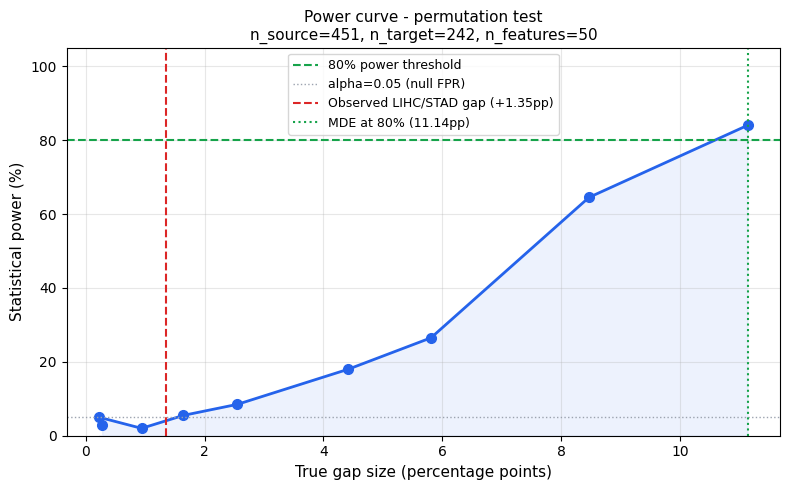

Figure saved: /kaggle/working/figures/mde_power_curve.svg


In [22]:
gaps = [r["mean_gap_pp"] for r in simulation_results]
power_pct = [r["power"] * 100 for r in simulation_results]

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(gaps, power_pct, marker="o", color="#2563eb", linewidth=2, markersize=7)
ax.axhline(80, color="#16a34a", linestyle="--", linewidth=1.5, label="80% power threshold")
ax.axhline(ALPHA * 100, color="#9ca3af", linestyle=":", linewidth=1, label=f"alpha={ALPHA} (null FPR)")
ax.axvline(observed_lihc_stad_gap_pp, color="#dc2626", linestyle="--", linewidth=1.5,
           label=f"Observed LIHC/STAD gap ({observed_lihc_stad_gap_pp:+.2f}pp)")

if mde_80:
    ax.axvline(mde_80, color="#16a34a", linestyle=":", linewidth=1.5, label=f"MDE at 80% ({mde_80:.2f}pp)")

ax.fill_between(gaps, power_pct, alpha=0.08, color="#2563eb")
ax.set_xlabel("True gap size (percentage points)", fontsize=11)
ax.set_ylabel("Statistical power (%)", fontsize=11)
ax.set_title(f"Power curve - permutation test\nn_source={N_SOURCE}, n_target={N_TARGET}, n_features={N_FEATURES}", fontsize=11)
ax.legend(fontsize=9)
ax.set_ylim(0, 105)
ax.grid(alpha=0.3)
plt.tight_layout()

svg_path = SVG_DIR / "mde_power_curve.svg"
plt.savefig(svg_path, format="svg", bbox_inches="tight")
plt.show()
print(f"Figure saved: {svg_path}")

## MDE comparison: single-split vs 5-fold cross-validation

In [23]:
def compute_audit_kfold(model, X_source, y_source, X_target, y_target, n_permutations=500, k=5, random_state=42):
    X_s = np.array(X_source)
    y_s = np.array(y_source)
    X_t = np.array(X_target)
    y_t = np.array(y_target)

    skf = StratifiedKFold(n_splits=k, shuffle=True, random_state=random_state)
    fold_source_correct = []
    fold_preds_target = []

    for train_idx, val_idx in skf.split(X_s, y_s):
        m = clone(model)
        m.fit(X_s[train_idx], y_s[train_idx])
        fold_source_correct.extend((m.predict(X_s[val_idx]) == y_s[val_idx]).astype(float))
        fold_preds_target.append(m.predict(X_t))

    correct_s = np.array(fold_source_correct)
    target_votes = np.array(fold_preds_target)
    correct_t_agg = (target_votes.mean(axis=0) >= 0.5).astype(float) == y_t

    source_acc = float(correct_s.mean())
    target_acc = float(correct_t_agg.mean())
    gap_pp = (source_acc - target_acc) * 100.0

    correct_t = correct_t_agg.astype(float)
    pooled = np.concatenate([correct_s, correct_t])
    n_s, n_t = len(correct_s), len(correct_t)
    rng = np.random.RandomState(random_state)

    perm_gaps = np.empty(n_permutations)
    for i in range(n_permutations):
        shuffled = rng.permutation(pooled)
        perm_gaps[i] = (shuffled[:n_s].mean() - shuffled[n_s:].mean()) * 100.0

    p_value = float(max(np.mean(np.abs(perm_gaps) >= np.abs(gap_pp)), 1.0 / n_permutations))

    m1, m2 = correct_s.mean(), correct_t.mean()
    s1, s2 = correct_s.std(ddof=1), correct_t.std(ddof=1)
    pooled_sd = np.sqrt(((n_s - 1) * s1**2 + (n_t - 1) * s2**2) / (n_s + n_t - 2))
    cohen_d = float((m1 - m2) / pooled_sd) if pooled_sd > 0 else 0.0

    return {
        "gap_pp": gap_pp, "p_value": p_value, "cohen_d": cohen_d,
        "source_accuracy": source_acc, "target_accuracy": target_acc,
        "correct_s": correct_s, "perm_gaps": perm_gaps,
    }


FLIP_RATES = [0.00, 0.01, 0.02, 0.03, 0.05, 0.07, 0.10, 0.13]
model = LogisticRegression(max_iter=500, random_state=RANDOM_STATE)
K_FOLDS = 5

print("MDE comparison: single-split vs 5-fold CV")
print(f"Parameters: n_source={N_SOURCE}, n_target={N_TARGET}, {N_TRIALS} trials")
print(f"\n{'Flip%':>5}  {'Mean gap':>9}  {'Single-split':>13}  {'5-fold CV':>10}")

single_powers, kfold_powers, mean_gaps = [], [], []

for flip_rate in FLIP_RATES:
    det_single = det_kfold = 0
    gaps_obs = []
    rng = np.random.RandomState(RANDOM_STATE + int(flip_rate * 10000))

    for trial in range(N_TRIALS):
        X_s = rng.randn(N_SOURCE, N_FEATURES)
        y_s = (X_s[:, 0] + X_s[:, 1] > 0).astype(int)
        X_t = rng.randn(N_TARGET, N_FEATURES)
        y_t = (X_t[:, 0] + X_t[:, 1] > 0).astype(int)

        if flip_rate > 0:
            n_flip = int(round(N_TARGET * flip_rate))
            flip_idx = rng.choice(N_TARGET, size=n_flip, replace=False)
            y_t[flip_idx] = 1 - y_t[flip_idx]

        r_s = compute_audit(model, X_s, y_s, X_t, y_t, n_permutations=N_PERM, random_state=trial)
        if r_s["p_value"] < ALPHA:
            det_single += 1
        gaps_obs.append(r_s["gap_pp"])

        r_k = compute_audit_kfold(model, X_s, y_s, X_t, y_t, n_permutations=N_PERM, k=K_FOLDS, random_state=trial)
        if r_k["p_value"] < ALPHA:
            det_kfold += 1

    p_single = det_single / N_TRIALS
    p_kfold = det_kfold / N_TRIALS
    mean_gap = float(np.mean(gaps_obs))

    single_powers.append(p_single)
    kfold_powers.append(p_kfold)
    mean_gaps.append(mean_gap)

    print(f"{flip_rate*100:>4.1f}%  {mean_gap:>+8.2f}pp  {p_single*100:>11.1f}%  {p_kfold*100:>8.1f}%")


def find_mde(powers, gaps):
    for p, g in zip(powers, gaps):
        if p >= 0.80:
            return g
    return None


mde_single = find_mde(single_powers, mean_gaps)
mde_kfold = find_mde(kfold_powers, mean_gaps)

print(f"\nMDE single-split: {f'{mde_single:.2f}pp' if mde_single else 'not reached'}")
print(f"MDE 5-fold CV: {f'{mde_kfold:.2f}pp' if mde_kfold else 'not reached'}")

if mde_single and mde_kfold:
    print(f"Improvement: {(mde_single - mde_kfold):.2f}pp reduction in MDE")

print("\nRetesting real cohorts with 5-fold CV...")

kfold_real_results = {}
for name, model_spec in base_algorithms.items():
    model_pipe = make_pipeline(
        StandardScaler(),
        PCA(n_components=50, random_state=RANDOM_STATE),
        clone(model_spec),
    )
    r = compute_audit_kfold(
        model_pipe, Xg_white, yg_white, Xg_asian, yg_asian,
        n_permutations=2000, k=K_FOLDS, random_state=RANDOM_STATE
    )
    sig = r["p_value"] < ALPHA
    kfold_real_results[name] = {
        "gap_pp": r["gap_pp"], "p_value": r["p_value"], "cohen_d": r["cohen_d"], "significant": sig,
    }
    print(f"{name:<5} | Gap: {r['gap_pp']:>+7.3f}pp | p: {r['p_value']:.4f} | d: {r['cohen_d']:.3f} | [{'SIG' if sig else 'OK'}]")

out = {
    "method_comparison": [
        {"flip_rate": fr, "mean_gap_pp": mg, "power_single": ps, "power_kfold": pk}
        for fr, mg, ps, pk in zip(FLIP_RATES, mean_gaps, single_powers, kfold_powers)
    ],
    "mde_single_pp": float(mde_single) if mde_single else None,
    "mde_kfold_pp": float(mde_kfold) if mde_kfold else None,
    "kfold_real_data_results": kfold_real_results,
}
save_path = RESULTS_DIR / "kfold_mde_comparison.json"
with save_path.open("w") as f:
    json.dump(out, f, indent=2)
print(f"\nSaved tracking checkpoint: {save_path}")

MDE comparison: single-split vs 5-fold CV
Parameters: n_source=451, n_target=242, 200 trials

Flip%   Mean gap   Single-split   5-fold CV
 0.0%     +0.27pp          3.0%       8.0%
 1.0%     +0.94pp          2.0%       2.5%
 2.0%     +1.64pp          5.5%       7.0%
 3.0%     +2.55pp          8.5%      14.0%
 5.0%     +4.42pp         18.0%      41.5%
 7.0%     +5.81pp         26.5%      68.0%
10.0%     +8.47pp         64.5%      92.0%
13.0%    +11.14pp         84.0%     100.0%

MDE single-split: 11.14pp
MDE 5-fold CV: 8.47pp
Improvement: 2.67pp reduction in MDE

Retesting real cohorts with 5-fold CV...
RF    | Gap:  +0.071pp | p: 1.0000 | d: 0.002 | [OK]
XGB   | Gap:  +0.413pp | p: 0.8870 | d: 0.014 | [OK]
LGB   | Gap:  -0.857pp | p: 0.7935 | d: -0.030 | [OK]
ET    | Gap:  +3.155pp | p: 0.2895 | d: 0.096 | [OK]
LR    | Gap:  -1.008pp | p: 0.7190 | d: -0.032 | [OK]
MLP   | Gap:  -2.016pp | p: 0.4700 | d: -0.059 | [OK]

Saved tracking checkpoint: /kaggle/working/results/kfold_mde_compari

## Learning curve

White-only baseline: 0.8685
n=10 (actual 10): mean acc 0.8712, 95% CI [0.8692, 0.8734]
n=25 (actual 25): mean acc 0.8782, 95% CI [0.8754, 0.8810]
n=50 (actual 50): mean acc 0.8826, 95% CI [0.8793, 0.8860]
n=75 (actual 75): mean acc 0.8865, 95% CI [0.8811, 0.8923]
n=100 (actual 100): mean acc 0.8934, 95% CI [0.8891, 0.8979]
n=125 (actual 125): mean acc 0.8941, 95% CI [0.8871, 0.9004]
n=150 (actual 150): mean acc 0.9048, 95% CI [0.8987, 0.9107]
Stabilization point: n approximately 50 Asian samples


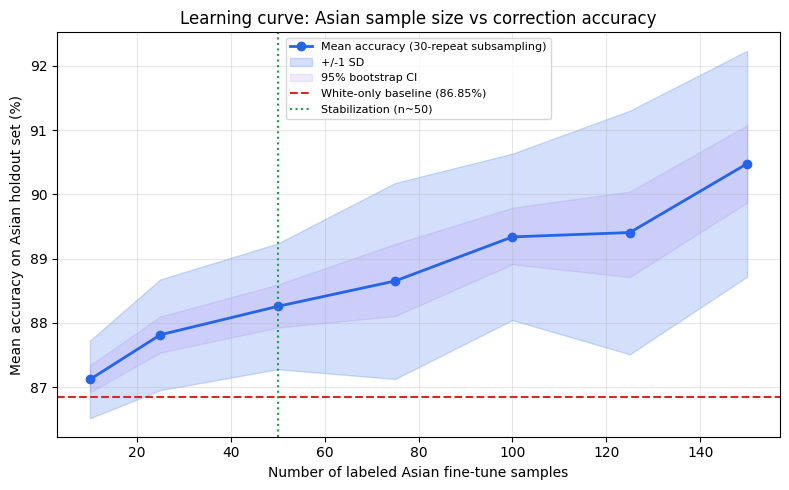

Saved: /kaggle/working/results/learning_curve.json


In [24]:
def run_learning_curve(Xg_white_train_pca, yg_white_train, Xg_asian_pca, yg_asian,
                        base_algorithms, n_values=None, n_repeats=30, n_bootstrap=1000):
    if n_values is None:
        n_values = [10, 25, 50, 75, 100, 125, 150]

    baseline_accs = []
    for name, model in base_algorithms.items():
        m = clone(model)
        m.fit(Xg_white_train_pca, yg_white_train)
        baseline_accs.append(accuracy_score(yg_asian, m.predict(Xg_asian_pca)))
    baseline_mean = np.mean(baseline_accs)

    print(f"White-only baseline: {baseline_mean:.4f}")

    idx_0 = np.where(yg_asian == 0)[0]
    idx_1 = np.where(yg_asian == 1)[0]
    rng = np.random.RandomState(RANDOM_STATE)

    lc_means, lc_sds, lc_ci_low, lc_ci_high, lc_n_actual = [], [], [], [], []

    for n in n_values:
        n_target = min(n, len(yg_asian))
        rep_accs = []
        n_used_list = []

        for _ in range(n_repeats):
            n0 = min(int(round(n_target * len(idx_0) / len(yg_asian))), len(idx_0))
            n1 = min(n_target - n0, len(idx_1))
            if n0 == 0 or n1 == 0:
                continue

            sel = np.concatenate([rng.choice(idx_0, n0, replace=False), rng.choice(idx_1, n1, replace=False)])
            hold_idx = np.setdiff1d(np.arange(len(yg_asian)), sel)

            X_sub, y_sub = Xg_asian_pca[sel], yg_asian[sel]
            X_hold, y_hold = Xg_asian_pca[hold_idx], yg_asian[hold_idx]
            if len(np.unique(y_hold)) < 2:
                continue

            X_comb = np.vstack([Xg_white_train_pca, X_sub])
            y_comb = np.concatenate([yg_white_train, y_sub])

            algo_accs = []
            for name, model in base_algorithms.items():
                m = clone(model)
                m.fit(X_comb, y_comb)
                algo_accs.append(accuracy_score(y_hold, m.predict(X_hold)))

            rep_accs.append(np.mean(algo_accs))
            n_used_list.append(n0 + n1)

        rep_accs = np.array(rep_accs)
        if len(rep_accs) == 0:
            print(f"n={n}: skipped, insufficient samples per class")
            continue

        boot_means = [np.mean(rng.choice(rep_accs, len(rep_accs), replace=True)) for _ in range(n_bootstrap)]
        ci_low, ci_high = np.percentile(boot_means, [2.5, 97.5])

        lc_means.append(np.mean(rep_accs))
        lc_sds.append(np.std(rep_accs, ddof=1) if len(rep_accs) > 1 else 0.0)
        lc_ci_low.append(ci_low)
        lc_ci_high.append(ci_high)
        lc_n_actual.append(int(np.mean(n_used_list)))

        print(f"n={n} (actual {int(np.mean(n_used_list))}): mean acc {np.mean(rep_accs):.4f}, 95% CI [{ci_low:.4f}, {ci_high:.4f}]")

    lc_means = np.array(lc_means)
    lc_sds = np.array(lc_sds)
    lc_ci_low = np.array(lc_ci_low)
    lc_ci_high = np.array(lc_ci_high)
    n_plotted = n_values[:len(lc_means)]

    gains = np.diff(lc_means) if len(lc_means) > 1 else np.array([])
    stable_idx = None
    for i, gain in enumerate(gains):
        if gain < 0.005:
            stable_idx = i + 1
            break
    stable_n = n_plotted[stable_idx] if stable_idx is not None else (n_plotted[-1] if len(n_plotted) else None)

    print(f"Stabilization point: n approximately {stable_n} Asian samples")

    fig, ax = plt.subplots(figsize=(8, 5))
    ax.plot(n_plotted, lc_means * 100, marker="o", color="#2563eb", linewidth=2, markersize=6,
            label=f"Mean accuracy ({n_repeats}-repeat subsampling)")
    ax.fill_between(n_plotted, (lc_means - lc_sds) * 100, (lc_means + lc_sds) * 100, alpha=0.2, color="#2563eb", label="+/-1 SD")
    ax.fill_between(n_plotted, lc_ci_low * 100, lc_ci_high * 100, alpha=0.1, color="#7c3aed", label="95% bootstrap CI")
    ax.axhline(baseline_mean * 100, color="#dc2626", linestyle="--", linewidth=1.5, label=f"White-only baseline ({baseline_mean*100:.2f}%)")
    if stable_n is not None:
        ax.axvline(stable_n, color="#16a34a", linestyle=":", linewidth=1.5, label=f"Stabilization (n~{stable_n})")
    ax.set_xlabel("Number of labeled Asian fine-tune samples")
    ax.set_ylabel("Mean accuracy on Asian holdout set (%)")
    ax.set_title("Learning curve: Asian sample size vs correction accuracy")
    ax.legend(fontsize=8)
    ax.grid(alpha=0.3)
    plt.tight_layout()

    svg_path = SVG_DIR / "learning_curve.svg"
    plt.savefig(svg_path, format="svg", bbox_inches="tight")
    plt.show()

    out = {
        "n_repeats": n_repeats, "n_requested": n_values[:len(lc_means)], "n_actual_mean": lc_n_actual,
        "means": lc_means.tolist(), "sds": lc_sds.tolist(),
        "ci_low": lc_ci_low.tolist(), "ci_high": lc_ci_high.tolist(),
        "baseline_mean": float(baseline_mean),
        "stabilization_n": int(stable_n) if stable_n is not None else None,
    }
    save_path = RESULTS_DIR / "learning_curve.json"
    with save_path.open("w") as f:
        json.dump(out, f, indent=2)
    print(f"Saved: {save_path}")
    return out


learning_curve_results = run_learning_curve(Xg_white_train_pca, yg_white_train, Xg_asian_pca, yg_asian, base_algorithms)

## Interpretability — SHAP (top-N)

/usr/local/lib/python3.13/dist-packages/shap/explainers/_linear.py:123: FutureWarning: The feature_perturbation option is now deprecated in favor of using the appropriate masker (maskers.Independent, maskers.Partition or maskers.Impute).
  warnings.warn(wmsg, FutureWarning)
Background dataset has 338 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=338 when initializing the masker.


Top 20 genes, White predictions:
 1. LINC02234            0.27321
 2. AC122697.1           0.27321
 3. HSPE1P10             0.27315
 4. BOLA3P3              0.27315
 5. LMNB1-DT             0.27315
 6. Y_RNA                0.22029
 7. RN7SL745P            0.12074
 8. MIR4741              0.11909
 9. RNU6-1032P           0.11887
10. LINC02753            0.11863
11. ARHGAP39             0.09756
12. ZNF16                0.09717
13. AC139103.1           0.09708
14. C8orf33              0.09708
15. ZNF250               0.09707
16. AL161851.1           0.07920
17. NPAS3                0.07920
18. AL161851.2           0.07920
19. RNU6-886P            0.07754
20. MIPOL1               0.07754

Top 20 genes, Asian predictions:
 1. LINC02234            0.31522
 2. AC122697.1           0.31522
 3. HSPE1P10             0.31515
 4. BOLA3P3              0.31515
 5. LMNB1-DT             0.31515
 6. Y_RNA                0.23061
 7. RN7SL745P            0.12240
 8. MIR4741              0.12072
 9. RNU6-

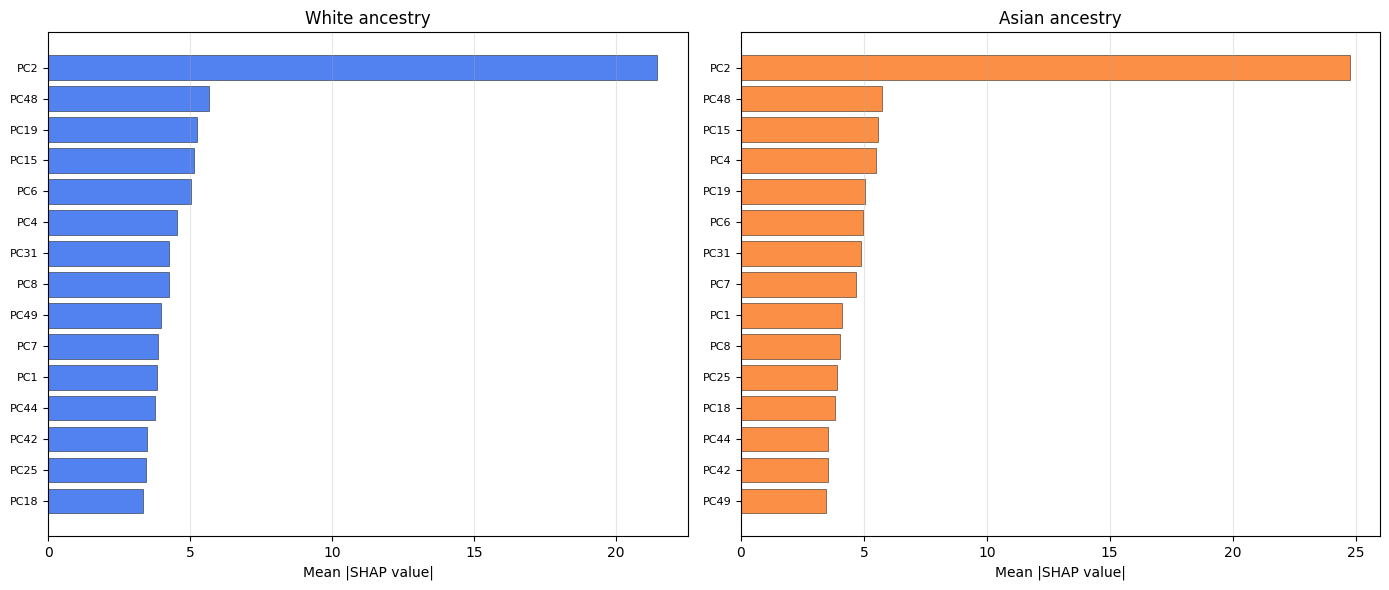

Saved: /kaggle/working/results/shap_report.json


In [25]:
def run_shap_analysis(Xg_white_train_pca, yg_white_train, Xg_white_test_pca, Xg_asian_pca, pca,
                       gene_list, gene_id_to_name, base_algorithms, y_white_test=None, y_asian=None, top_n=20):
    lr = clone(base_algorithms["LR"])
    lr.fit(Xg_white_train_pca, yg_white_train)

    explainer = shap.LinearExplainer(lr, Xg_white_train_pca, feature_perturbation="interventional")
    shap_white = explainer.shap_values(Xg_white_test_pca)
    shap_asian = explainer.shap_values(Xg_asian_pca)

    imp_white = np.abs(shap_white).mean(axis=0)
    imp_asian = np.abs(shap_asian).mean(axis=0)

    top_white_idx = np.argsort(imp_white)[::-1][:top_n]
    top_asian_idx = np.argsort(imp_asian)[::-1][:top_n]

    def top_genes_for_components(component_indices, importance, n_genes=5):
        contributions = {}
        for pc_idx in component_indices:
            loadings = np.abs(pca.components_[pc_idx])
            weight = importance[pc_idx]
            top_gene_idx = np.argsort(loadings)[::-1][:n_genes]
            for gi in top_gene_idx:
                gname = gene_id_to_name.get(gene_list[gi], gene_list[gi])
                contributions[gname] = contributions.get(gname, 0.0) + weight * loadings[gi]
        return sorted(contributions.items(), key=lambda x: -x[1])

    white_genes = top_genes_for_components(top_white_idx, imp_white)
    asian_genes = top_genes_for_components(top_asian_idx, imp_asian)
    white_gene_names = [g[0] for g in white_genes[:top_n]]
    asian_gene_names = [g[0] for g in asian_genes[:top_n]]

    asian_specific = [g for g in asian_gene_names if g not in white_gene_names]
    white_specific = [g for g in white_gene_names if g not in asian_gene_names]

    print(f"Top {top_n} genes, White predictions:")
    for i, (gname, score) in enumerate(white_genes[:top_n], 1):
        print(f"{i:>2}. {gname:<20} {score:.5f}")

    print(f"\nTop {top_n} genes, Asian predictions:")
    for i, (gname, score) in enumerate(asian_genes[:top_n], 1):
        print(f"{i:>2}. {gname:<20} {score:.5f}")

    print(f"\nAsian-specific drivers: {asian_specific}")
    print(f"White-specific drivers: {white_specific}")

    confound_note = None
    if y_white_test is not None and y_asian is not None:
        white_ratio = np.mean(y_white_test)
        asian_ratio = np.mean(y_asian)
        print(f"\nClass ratio: White {white_ratio:.3f}, Asian {asian_ratio:.3f}")
        if abs(white_ratio - asian_ratio) > 0.05:
            confound_note = (f"Class composition differs by cohort ({white_ratio:.2f} vs {asian_ratio:.2f}). "
                             f"SHAP divergence may reflect this rather than ancestry-specific biology.")
            print(confound_note)
    else:
        confound_note = "y_white_test/y_asian not provided, confound check skipped."
        print(f"\n{confound_note}")

    fig, axes = plt.subplots(1, 2, figsize=(14, 6))

    def plot_bar(ax, importances, indices, title, color):
        top = indices[:15]
        vals = importances[top]
        labels = [f"PC{i+1}" for i in top]
        ax.barh(range(len(top)), vals[::-1], color=color, alpha=0.8, edgecolor="black", linewidth=0.4)
        ax.set_yticks(range(len(top)))
        ax.set_yticklabels(labels[::-1], fontsize=8)
        ax.set_xlabel("Mean |SHAP value|")
        ax.set_title(title)
        ax.grid(axis="x", alpha=0.3)

    plot_bar(axes[0], imp_white, top_white_idx, "White ancestry", "#2563eb")
    plot_bar(axes[1], imp_asian, top_asian_idx, "Asian ancestry", "#f97316")
    plt.tight_layout()

    svg_path = SVG_DIR / "shap_white_vs_asian.svg"
    plt.savefig(svg_path, format="svg", bbox_inches="tight")
    plt.show()

    out = {
        "white_top_genes": white_gene_names, "asian_top_genes": asian_gene_names,
        "asian_specific_genes": asian_specific, "white_specific_genes": white_specific,
        "confound_note": confound_note,
    }
    save_path = RESULTS_DIR / "shap_report.json"
    with save_path.open("w") as f:
        json.dump(out, f, indent=2)
    print(f"Saved: {save_path}")
    return out


shap_results = run_shap_analysis(
    Xg_white_train_pca, yg_white_train, Xg_white_test_pca, Xg_asian_pca, pca,
    GENE_LIST, gene_id_to_name, base_algorithms, y_white_test=yg_white_test, y_asian=yg_asian
)

## CORAL baseline (unsupervised domain adaptation)

In [26]:
def compute_coral_transform(X_source, X_target, lambda_reg=1.0):
    source_mean = X_source.mean(axis=0)
    Xs_c = X_source - source_mean
    Xt_c = X_target - X_target.mean(axis=0)

    n_feat = X_source.shape[1]
    cov_s = np.cov(Xs_c, rowvar=False) + lambda_reg * np.eye(n_feat)
    cov_t = np.cov(Xt_c, rowvar=False) + lambda_reg * np.eye(n_feat)

    cov_s_inv_sqrt = fractional_matrix_power(cov_s, -0.5).real
    cov_t_sqrt = fractional_matrix_power(cov_t, 0.5).real

    return cov_s_inv_sqrt @ cov_t_sqrt, source_mean


def apply_coral(X, transform_matrix, source_mean):
    return (X - source_mean) @ transform_matrix + source_mean


coral_matrix, white_mean = compute_coral_transform(Xg_white_train_pca, Xg_asian_pca)

Xg_white_train_coral = apply_coral(Xg_white_train_pca, coral_matrix, white_mean)
Xg_white_test_coral = apply_coral(Xg_white_test_pca, coral_matrix, white_mean)

coral_results = {}

print(f"{'Algo':<5} {'W-Acc':>8} {'A-Acc':>8} {'PGI':>8} {'No-adapt A':>11} {'Delta':>8}")

for name, model in base_algorithms.items():
    m = clone(model)
    m.fit(Xg_white_train_coral, yg_white_train)

    acc_w = accuracy_score(yg_white_test, m.predict(Xg_white_test_coral))
    acc_a = accuracy_score(yg_asian, m.predict(Xg_asian_pca))
    pgi = acc_w - acc_a

    baseline_a = results_pca[name]["asian_acc"]
    delta = acc_a - baseline_a

    coral_results[name] = {
        "white_acc": acc_w, "asian_acc": acc_a, "pgi": pgi,
        "no_adapt_asian_acc": baseline_a, "delta": delta,
    }

    print(f"{name:<5} {acc_w:>8.3f} {acc_a:>8.3f} {pgi:>+8.3f} {baseline_a:>11.3f} {delta:>+8.3f}")

save_path = RESULTS_DIR / "coral_results.json"
with save_path.open("w") as f:
    json.dump(coral_results, f, indent=2)
print(f"Saved: {save_path}")

Algo     W-Acc    A-Acc      PGI  No-adapt A    Delta
RF       0.938    0.872   +0.066       0.880   -0.008
XGB      0.929    0.868   +0.061       0.897   -0.029
LGB      0.912    0.847   +0.064       0.884   -0.037
ET       0.885    0.831   +0.054       0.851   -0.021
LR       0.912    0.864   +0.048       0.897   -0.033
MLP      0.832    0.789   +0.043       0.802   -0.012
Saved: /kaggle/working/results/coral_results.json


## Junk-gene filtering + SHAP v2 (divergence-weighted)

In [27]:
gene_symbols = [gene_id_to_name.get(g, g) for g in GENE_LIST]

Xg_white_filt, kept_genes, filter_log = filter_stratification_noise(Xg_white_train, gene_symbols, gene_biotype=None)

print(f"Removed {filter_log['n_removed']} genes, kept {len(kept_genes)}")

Removed 34304 genes, kept 26319


/usr/local/lib/python3.13/dist-packages/shap/explainers/_linear.py:123: FutureWarning: The feature_perturbation option is now deprecated in favor of using the appropriate masker (maskers.Independent, maskers.Partition or maskers.Impute).
  warnings.warn(wmsg, FutureWarning)
Background dataset has 338 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=338 when initializing the masker.


Top 20 divergent genes (weighted, filtered=True):
 1. Y_RNA                0.04757
 2. LINC02234            0.04202
 3. LMNB1-DT             0.04201
 4. TEX43                0.04201
 5. PHAX                 0.04201
 6. LINC01843            0.04183
 7. U6                   0.01587
 8. VDAC2                0.01171
 9. KAT6B                0.01151
10. ZNF503-AS1           0.01079
11. ACOT7                0.01070
12. OXR1                 0.01055
13. ABRA                 0.01055
14. ENY2                 0.01053
15. NUDCD1               0.01053
16. ZNF503-AS2           0.01046
17. PLEKHG5              0.01045
18. HES2                 0.01043
19. TNFRSF25             0.01043
20. MIR4252              0.01043

Class ratio: White 0.398, Asian 0.645
Class composition differs (0.40 vs 0.64). Divergence-selected genes may reflect this rather than ancestry-specific biology.


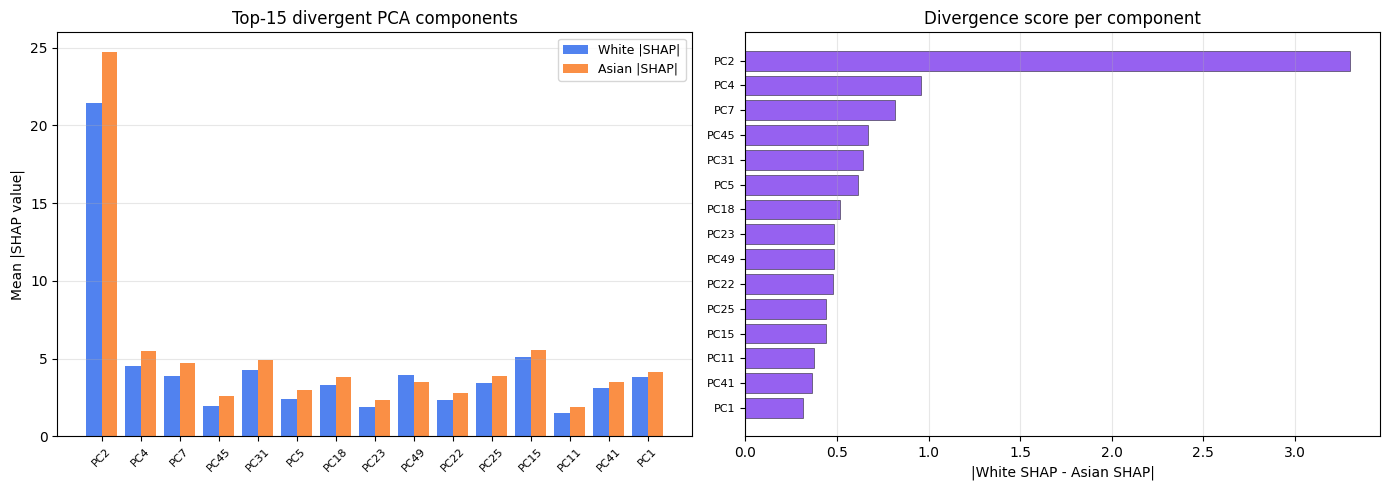

Saved: /kaggle/working/results/shap_report_v2.json


In [28]:
def run_shap_analysis_v2(Xg_white_train_pca, yg_white_train, Xg_white_test_pca, Xg_asian_pca, pca,
                          gene_list, gene_id_to_name, base_algorithms, kept_genes=None,
                          y_white_test=None, y_asian=None, top_n=20):
    lr = clone(base_algorithms["LR"])
    lr.fit(Xg_white_train_pca, yg_white_train)

    explainer = shap.LinearExplainer(lr, Xg_white_train_pca, feature_perturbation="interventional")
    shap_white = explainer.shap_values(Xg_white_test_pca)
    shap_asian = explainer.shap_values(Xg_asian_pca)

    imp_white = np.abs(shap_white).mean(axis=0)
    imp_asian = np.abs(shap_asian).mean(axis=0)
    divergence = np.abs(imp_white - imp_asian)

    top_div_idx = np.argsort(divergence)[::-1][:top_n]
    top_white_idx = np.argsort(imp_white)[::-1][:top_n]
    top_asian_idx = np.argsort(imp_asian)[::-1][:top_n]

    if kept_genes is None:
        print("kept_genes not provided, junk-gene filtering not applied")
        kept_genes_set = None
    else:
        kept_genes_set = set(kept_genes)

    def gene_ok(gname):
        return kept_genes_set is None or gname in kept_genes_set

    def top_genes_weighted(component_indices, weight_array, n_genes=5):
        contributions = {}
        for pc_idx in component_indices:
            loadings = np.abs(pca.components_[pc_idx])
            weight = weight_array[pc_idx]
            order = np.argsort(loadings)[::-1]
            count = 0
            for gi in order:
                gname = gene_id_to_name.get(gene_list[gi], gene_list[gi])
                if not gene_ok(gname):
                    continue
                contributions[gname] = contributions.get(gname, 0.0) + weight * loadings[gi]
                count += 1
                if count >= n_genes:
                    break
        return sorted(contributions.items(), key=lambda x: -x[1])

    div_genes = top_genes_weighted(top_div_idx, divergence)
    white_genes = top_genes_weighted(top_white_idx, imp_white)
    asian_genes = top_genes_weighted(top_asian_idx, imp_asian)

    div_names = [g[0] for g in div_genes[:top_n]]
    white_names = [g[0] for g in white_genes[:top_n]]
    asian_names = [g[0] for g in asian_genes[:top_n]]

    print(f"Top {top_n} divergent genes (weighted, filtered={kept_genes_set is not None}):")
    for i, (gname, score) in enumerate(div_genes[:top_n], 1):
        print(f"{i:>2}. {gname:<20} {score:.5f}")

    confound_note = None
    if y_white_test is not None and y_asian is not None:
        white_ratio = np.mean(y_white_test)
        asian_ratio = np.mean(y_asian)
        print(f"\nClass ratio: White {white_ratio:.3f}, Asian {asian_ratio:.3f}")
        if abs(white_ratio - asian_ratio) > 0.05:
            confound_note = (f"Class composition differs ({white_ratio:.2f} vs {asian_ratio:.2f}). "
                             f"Divergence-selected genes may reflect this rather than ancestry-specific biology.")
            print(confound_note)
    else:
        confound_note = "y_white_test/y_asian not provided, confound check skipped."
        print(f"\n{confound_note}")

    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    ax = axes[0]
    pcs = [f"PC{i+1}" for i in top_div_idx[:15]]
    w_imp = imp_white[top_div_idx[:15]]
    a_imp = imp_asian[top_div_idx[:15]]
    x = np.arange(len(pcs))
    ax.bar(x - 0.2, w_imp, 0.4, label="White |SHAP|", color="#2563eb", alpha=0.8)
    ax.bar(x + 0.2, a_imp, 0.4, label="Asian |SHAP|", color="#f97316", alpha=0.8)
    ax.set_xticks(x)
    ax.set_xticklabels(pcs, rotation=45, fontsize=8)
    ax.set_ylabel("Mean |SHAP value|")
    ax.set_title("Top-15 divergent PCA components")
    ax.legend(fontsize=9)
    ax.grid(axis="y", alpha=0.3)

    ax2 = axes[1]
    divs = divergence[top_div_idx[:15]]
    ax2.barh(range(len(pcs)), divs[::-1], color="#7c3aed", alpha=0.8, edgecolor="black", linewidth=0.4)
    ax2.set_yticks(range(len(pcs)))
    ax2.set_yticklabels(pcs[::-1], fontsize=8)
    ax2.set_xlabel("|White SHAP - Asian SHAP|")
    ax2.set_title("Divergence score per component")
    ax2.grid(axis="x", alpha=0.3)
    plt.tight_layout()

    svg_path = SVG_DIR / "shap_divergence_v2.svg"
    plt.savefig(svg_path, format="svg", bbox_inches="tight")
    plt.show()

    out = {
        "divergent_genes": div_names, "white_top_genes": white_names, "asian_top_genes": asian_names,
        "junk_filter_applied": kept_genes_set is not None, "confound_note": confound_note,
    }
    save_path = RESULTS_DIR / "shap_report_v2.json"
    with save_path.open("w") as f:
        json.dump(out, f, indent=2)
    print(f"Saved: {save_path}")
    return out


shap_results_v2 = run_shap_analysis_v2(
    Xg_white_train_pca, yg_white_train, Xg_white_test_pca, Xg_asian_pca, pca,
    GENE_LIST, gene_id_to_name, base_algorithms,
    kept_genes=kept_genes, y_white_test=yg_white_test, y_asian=yg_asian,
)

## Supervised fine-tuning correction

In [29]:
def run_finetuning_robustness(Xg_white_train_pca, yg_white_train, Xg_asian_pca, yg_asian,
                               base_algorithms, seeds=None):
    if seeds is None:
        seeds = [42, 0, 1, 7, 13, 17, 21, 99, 123, 256]

    seed_results = []
    for seed in seeds:
        X_ft, X_hold, y_ft, y_hold = train_test_split(
            Xg_asian_pca, yg_asian, test_size=0.5, random_state=seed, stratify=yg_asian
        )
        X_combined = np.vstack([Xg_white_train_pca, X_ft])
        y_combined = np.concatenate([yg_white_train, y_ft])

        algo_deltas = []
        for name, model in base_algorithms.items():
            m_base = clone(model)
            m_base.fit(Xg_white_train_pca, yg_white_train)
            acc_base = accuracy_score(y_hold, m_base.predict(X_hold))

            m_ft = clone(model)
            m_ft.fit(X_combined, y_combined)
            acc_ft = accuracy_score(y_hold, m_ft.predict(X_hold))

            algo_deltas.append(acc_ft - acc_base)

        mean_delta = np.mean(algo_deltas)
        seed_results.append(mean_delta)
        print(f"seed {seed}: mean delta {mean_delta*100:+.2f}pp")

    seed_results = np.array(seed_results)

    print(f"\nmean correction: {seed_results.mean()*100:+.2f}pp")
    print(f"sd: {seed_results.std(ddof=1)*100:.2f}pp")
    print(f"positive runs: {(seed_results > 0).sum()}/{len(seeds)}")

    out = {
        "seeds": seeds, "per_seed_delta": seed_results.tolist(),
        "mean": float(seed_results.mean()), "sd": float(seed_results.std(ddof=1)),
        "min": float(seed_results.min()), "max": float(seed_results.max()),
        "all_positive": bool(np.all(seed_results > 0)), "n_positive": int((seed_results > 0).sum()),
    }
    save_path = RESULTS_DIR / "finetuning_robustness.json"
    with save_path.open("w") as f:
        json.dump(out, f, indent=2)
    print(f"Saved: {save_path}")
    return out


def bootstrap_correction_ci(Xg_white_train_pca, yg_white_train, Xg_asian_pca, yg_asian,
                             base_algorithms, n_bootstrap=1000):
    X_ft, X_hold, y_ft, y_hold = train_test_split(
        Xg_asian_pca, yg_asian, test_size=0.5, random_state=RANDOM_STATE, stratify=yg_asian
    )
    X_combined = np.vstack([Xg_white_train_pca, X_ft])
    y_combined = np.concatenate([yg_white_train, y_ft])

    models_base, models_ft = {}, {}
    for name, model in base_algorithms.items():
        mb = clone(model)
        mb.fit(Xg_white_train_pca, yg_white_train)
        models_base[name] = mb

        mf = clone(model)
        mf.fit(X_combined, y_combined)
        models_ft[name] = mf

    rng = np.random.RandomState(RANDOM_STATE)
    boot_deltas = []
    for _ in range(n_bootstrap):
        idx = rng.choice(len(y_hold), size=len(y_hold), replace=True)
        X_b, y_b = X_hold[idx], y_hold[idx]
        algo_deltas = []
        for name in base_algorithms:
            acc_base = accuracy_score(y_b, models_base[name].predict(X_b))
            acc_ft = accuracy_score(y_b, models_ft[name].predict(X_b))
            algo_deltas.append(acc_ft - acc_base)
        boot_deltas.append(np.mean(algo_deltas))

    boot_deltas = np.array(boot_deltas)
    mean_delta = np.mean(boot_deltas)
    ci_low, ci_high = np.percentile(boot_deltas, [2.5, 97.5])

    print(f"mean correction: {mean_delta*100:+.2f}pp")
    print(f"95% CI: [{ci_low*100:+.2f}pp, {ci_high*100:+.2f}pp]")

    out = {
        "mean_delta": float(mean_delta), "ci_low": float(ci_low), "ci_high": float(ci_high),
        "directionality_confirmed": bool(ci_low > 0), "n_bootstrap": n_bootstrap,
    }
    save_path = RESULTS_DIR / "bootstrap_correction_ci.json"
    with save_path.open("w") as f:
        json.dump(out, f, indent=2)
    print(f"Saved: {save_path}")
    return out


finetuning_out = run_finetuning_robustness(Xg_white_train_pca, yg_white_train, Xg_asian_pca, yg_asian, base_algorithms)
bootstrap_out = bootstrap_correction_ci(Xg_white_train_pca, yg_white_train, Xg_asian_pca, yg_asian, base_algorithms)

seed 42: mean delta +2.48pp
seed 0: mean delta +1.93pp
seed 1: mean delta +3.72pp
seed 7: mean delta +1.93pp
seed 13: mean delta +2.75pp
seed 17: mean delta +3.03pp
seed 21: mean delta +2.20pp
seed 99: mean delta +3.03pp
seed 123: mean delta +3.31pp
seed 256: mean delta +2.62pp

mean correction: +2.70pp
sd: 0.59pp
positive runs: 10/10
Saved: /kaggle/working/results/finetuning_robustness.json
mean correction: +2.48pp
95% CI: [+0.69pp, +4.41pp]
Saved: /kaggle/working/results/bootstrap_correction_ci.json


## Final summary

In [30]:
def print_summary(leakage_report, main_n_significant_acc, main_n_significant_bal, control_results,
                   thca_blca_results, phase3_results, mde_80, mde_kfold, finetuning_out,
                   bootstrap_out, coral_results, base_algorithms):
    critical = any("CRITICAL" in v["status"] for v in leakage_report.values())

    print("Pipeline integrity")
    print("CLEAN" if not critical else "CRITICAL LEAK DETECTED")

    print("\nMain audit (LIHC/STAD, permutation test with Holm correction)")
    print(f"Accuracy: {main_n_significant_acc}/6 significant")
    print(f"Balanced accuracy: {main_n_significant_bal}/6 significant")

    print("\nNegative control 1 (COAD/LUAD)")
    print(f"Verdict: {control_results['verdict']}")
    print(f"Accuracy: {control_results['nc_accuracy_n_significant']}/6, "
          f"balanced accuracy: {control_results['nc_balanced_accuracy_n_significant']}/6")

    print("\nNegative control 2 (THCA/BLCA)")
    print(f"Verdict: {thca_blca_results['verdict']}")
    print(f"Accuracy: {thca_blca_results['nc_accuracy_n_significant']}/6, "
          f"balanced accuracy: {thca_blca_results['nc_balanced_accuracy_n_significant']}/6")

    print("\nGeneralizability (ESCA/STAD)")
    print(f"Verdict: {phase3_results['verdict']}")
    print(f"Accuracy: {phase3_results['n_sig_acc']}/6, balanced accuracy: {phase3_results['n_sig_bal']}/6")
    print(f"Class ratio chi2 p = {phase3_results['class_ratio_p']:.2e}")

    print("\nStatistical power")

    def fmt_mde(value):
        return f"{value:.2f}pp" if value is not None else "not reached in tested range"
    print(f"MDE at 80% power, single-split: {fmt_mde(mde_80)}")
    print(f"MDE at 80% power, 5-fold CV: {fmt_mde(mde_kfold)}")

    print("\nSupervised fine-tuning correction (10 seeds)")
    print(f"Mean delta: {finetuning_out['mean']*100:+.2f}pp")
    print(f"Positive runs: {finetuning_out['n_positive']}/{len(finetuning_out['seeds'])}")
    print(f"95% bootstrap CI: [{bootstrap_out['ci_low']*100:+.2f}pp, {bootstrap_out['ci_high']*100:+.2f}pp]")

    print("\nCORAL baseline (unsupervised)")
    for name, r in coral_results.items():
        print(f"{name:<5} delta {r['delta']*100:+.2f}pp")

    summary = {
        "pipeline_status": "CLEAN" if not critical else "CRITICAL_LEAK",
        "main_audit": {"n_significant_acc": main_n_significant_acc, "n_significant_bal": main_n_significant_bal},
        "negative_control_coad_luad": control_results["verdict"],
        "negative_control_thca_blca": thca_blca_results["verdict"],
        "generalizability_esca_stad": phase3_results["verdict"],
        "mde_single_pp": mde_80,
        "mde_kfold_pp": mde_kfold,
        "correction_mean_delta_pp": finetuning_out["mean"] * 100,
        "correction_ci_pp": [bootstrap_out["ci_low"] * 100, bootstrap_out["ci_high"] * 100],
    }
    save_path = RESULTS_DIR / "final_summary.json"
    with save_path.open("w") as f:
        json.dump(summary, f, indent=2)
    print(f"\nSaved: {save_path}")
    return summary


final_summary = print_summary(
    leakage_report, main_n_significant_acc, main_n_significant_bal, control_results,
    thca_blca_results, phase3_results, mde_80, mde_kfold, finetuning_out, bootstrap_out,
    coral_results, base_algorithms,
)

Pipeline integrity
CLEAN

Main audit (LIHC/STAD, permutation test with Holm correction)
Accuracy: 0/6 significant
Balanced accuracy: 0/6 significant

Negative control 1 (COAD/LUAD)
Verdict: PASSED
Accuracy: 0/6, balanced accuracy: 0/6

Negative control 2 (THCA/BLCA)
Verdict: FAILED
Accuracy: 1/6, balanced accuracy: 3/6

Generalizability (ESCA/STAD)
Verdict: PASSED_NO_BIAS
Accuracy: 0/6, balanced accuracy: 0/6
Class ratio chi2 p = 4.40e-01

Statistical power
MDE at 80% power, single-split: 11.14pp
MDE at 80% power, 5-fold CV: 8.47pp

Supervised fine-tuning correction (10 seeds)
Mean delta: +2.70pp
Positive runs: 10/10
95% bootstrap CI: [+0.69pp, +4.41pp]

CORAL baseline (unsupervised)
RF    delta -0.83pp
XGB   delta -2.89pp
LGB   delta -3.72pp
ET    delta -2.07pp
LR    delta -3.31pp
MLP   delta -1.24pp

Saved: /kaggle/working/results/final_summary.json
